# 电信客户流失分析

数据是 `telco.csv` 的一次性历史快照（7043 行，21 列）。目标列是 `Churn`。
随机种子固定为 42。先清洗和画画像，再切分训练 / 验证 / 留出集，最后用留出集模拟本周要打分的存量客户。

环境：conda 环境 `data-analysis`。


In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import font_manager
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

import lightgbm as lgb
import sklearn
import statsmodels.formula.api as smf
import xgboost

warnings.filterwarnings(
    "ignore",
    message="Found unknown categories",
    category=UserWarning,
)

RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / "telco.csv").exists():
    ROOT = Path(__file__).resolve().parent
DATA_PATH = ROOT / "telco.csv"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
MODEL_DIR = OUT / "models"
for folder in (OUT, FIG, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

np.random.seed(RANDOM_STATE)

CONTRACT_MAP = {"Month-to-month": 0, "One year": 1, "Two year": 2}
CAT_COLS = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling",
    "PaymentMethod",
]
NOTES: list[str] = []


def setup_font() -> str:
    candidates = [
        "/System/Library/Fonts/PingFang.ttc",
        "/System/Library/Fonts/STHeiti Light.ttc",
        "/System/Library/Fonts/Supplemental/Arial Unicode.ttf",
        "/Library/Fonts/Arial Unicode.ttf",
    ]
    chosen = None
    for path in candidates:
        if Path(path).exists():
            font_manager.fontManager.addfont(path)
            chosen = font_manager.FontProperties(fname=path).get_name()
            break
    sns.set_theme(style="whitegrid")
    if chosen:
        plt.rcParams["font.family"] = chosen
        plt.rcParams["font.sans-serif"] = [chosen]
    plt.rcParams["axes.unicode_minus"] = False
    return chosen or "default"


FONT_NAME = setup_font()
PALETTE = {"No": "#4C78A8", "Yes": "#E45756"}


def section(title: str) -> None:
    print("\n" + "=" * 72)
    print(title)
    print("=" * 72)


def note(text: str) -> None:
    NOTES.append(text)
    print("结论：" + text)


def save_fig(fig: plt.Figure, name: str) -> None:
    path = FIG / name
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.close(fig)
    print(f"[图] {path.relative_to(ROOT)}")
    try:
        from IPython import get_ipython

        if get_ipython() is not None:
            from IPython.display import Image, display

            display(Image(filename=str(path)))
    except Exception:
        pass


def churn_rate_table(frame: pd.DataFrame, col: str) -> pd.DataFrame:
    tmp = frame.assign(_y=(frame["Churn"] == "Yes").astype(int))
    out = tmp.groupby(col, dropna=False)["_y"].agg(n="size", churned="sum")
    out["churn_rate"] = out["churned"] / out["n"]
    return out.sort_values("churn_rate", ascending=False)


def rate_of(frame: pd.DataFrame) -> float:
    return float((frame["Churn"] == "Yes").mean())


def plot_by_churn(frame: pd.DataFrame, columns: list[str], title: str, filename: str) -> None:
    n = len(columns)
    fig, axes = plt.subplots(n, 2, figsize=(11.5, 3.6 * n), constrained_layout=True)
    axes = np.atleast_2d(axes)
    for row, col in enumerate(columns):
        order = frame[col].value_counts().index.tolist()
        sns.countplot(
            data=frame,
            x=col,
            hue="Churn",
            order=order,
            hue_order=["No", "Yes"],
            palette=PALETTE,
            ax=axes[row, 0],
        )
        axes[row, 0].set_title(f"{col}：人数（按是否流失着色）")
        axes[row, 0].set_xlabel("")
        axes[row, 0].set_ylabel("客户数")
        axes[row, 0].tick_params(axis="x", rotation=15)

        rates = churn_rate_table(frame, col).reindex(order)
        colors = ["#E45756" if r > frame_churn else "#4C78A8" for r in rates["churn_rate"]]
        axes[row, 1].bar(rates.index.astype(str), rates["churn_rate"], color=colors)
        axes[row, 1].axhline(frame_churn, color="#333333", ls="--", lw=1, label="整体流失率")
        axes[row, 1].set_ylim(0, max(0.55, float(rates["churn_rate"].max()) + 0.08))
        axes[row, 1].set_title(f"{col}：流失率")
        axes[row, 1].set_xlabel("")
        axes[row, 1].set_ylabel("流失率")
        axes[row, 1].tick_params(axis="x", rotation=15)
        axes[row, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        if row == 0:
            axes[row, 1].legend(loc="upper right", fontsize=8)
        for label, value, count in zip(rates.index.astype(str), rates["churn_rate"], rates["n"]):
            axes[row, 1].text(label, value + 0.01, f"{value:.0%}", ha="center", va="bottom", fontsize=8)
    fig.suptitle(title, fontsize=14)
    save_fig(fig, filename)


def yes_flag(series: pd.Series) -> pd.Series:
    return (series == "Yes").astype(int)


def classification_report(y_true: np.ndarray, proba: np.ndarray, threshold: float) -> dict:
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_true, pred)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, proba)),
        "predicted_positive_rate": float(pred.mean()),
        "confusion_matrix": confusion_matrix(y_true, pred).tolist(),
    }


def build_lgb_frame(frame: pd.DataFrame, levels: dict[str, list[str]] | None = None):
    fitted = {} if levels is None else levels
    data = {
        "SeniorCitizen": frame["SeniorCitizen"].astype(int),
        "tenure": frame["tenure"].astype(float),
        "MonthlyCharges": frame["MonthlyCharges"].astype(float),
        "TotalCharges": frame["TotalCharges"].astype(float),
        "Contract": frame["Contract"].map(CONTRACT_MAP).astype(int),
    }
    X = pd.DataFrame(data, index=frame.index)
    for col in CAT_COLS:
        if levels is None:
            fitted[col] = sorted(frame[col].astype(str).unique().tolist())
        X[col] = pd.Categorical(frame[col].astype(str), categories=fitted[col])
    if X.isna().any().any():
        missing = X.columns[X.isna().any()].tolist()
        raise ValueError(f"特征出现缺失，编码没有覆盖：{missing}")
    return X, fitted


section("0. 环境")
versions = {
    "python_font": FONT_NAME,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "sklearn": sklearn.__version__,
    "lightgbm": lgb.__version__,
    "xgboost": xgboost.__version__,
}
print(json.dumps(versions, ensure_ascii=False, indent=2))
print("导入检查通过：pandas、numpy、matplotlib、seaborn、scikit-learn、xgboost、lightgbm")
print(f"random_state = {RANDOM_STATE}")
print(f"数据文件 = {DATA_PATH}")



0. 环境
{
  "python_font": "Heiti TC",
  "pandas": "3.1.0",
  "numpy": "2.4.6",
  "sklearn": "1.9.1",
  "lightgbm": "4.7.0",
  "xgboost": "3.4.2"
}
导入检查通过：pandas、numpy、matplotlib、seaborn、scikit-learn、xgboost、lightgbm
random_state = 42
数据文件 = /Users/zhhyowner/project/github/telecom-churn-analysis-model/telco.csv


## 1. 认清每一列

`customerID` 只用于最后的名单。`Churn` 是要预测的答案。`TotalCharges` 先按字符串读入，避免空字符串被静默当成缺失后看不出来。


In [2]:
section("1. 读入数据")
raw = pd.read_csv(DATA_PATH, dtype={"TotalCharges": "string"})
print(f"行数 {len(raw)}，列数 {raw.shape[1]}")
print("列类型：")
print(raw.dtypes.to_string())
print("\n前 5 行：")
print(raw.head().to_string())
print("\n分类列取值人数：")
cat_preview = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "Churn",
]
for col in cat_preview:
    print(f"\n[{col}]")
    print(raw[col].value_counts(dropna=False).to_string())



1. 读入数据
行数 7043，列数 21
列类型：
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges         string
Churn                   str

前 5 行：
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling              PaymentMethod  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0     Yes         No       1           No  No phon

## 2. 清洗

`TotalCharges` 的空字符串应对应 `tenure = 0` 的新客户，填 0，再转成浮点数。不用上一行的金额去补。


In [3]:
section("2. 清洗")
total_text = raw["TotalCharges"].fillna("").str.strip()
blank = total_text.eq("")
print(f"表面上的 NaN 数：{int(raw.isna().sum().sum())}")
print(f"TotalCharges 空字符串数：{int(blank.sum())}")
blank_rows = raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
print(blank_rows.to_string(index=False))
if not (blank_rows["tenure"].astype(int) == 0).all():
    raise AssertionError("空的 TotalCharges 并不都是 tenure=0，不能直接填 0")

clean = raw.copy()
clean["TotalCharges"] = total_text.mask(blank, "0").astype(float)
clean["MonthlyCharges"] = clean["MonthlyCharges"].astype(float)
clean["tenure"] = clean["tenure"].astype(int)
clean["SeniorCitizen"] = clean["SeniorCitizen"].astype(int)
clean["customerID"] = clean["customerID"].astype(str)

assert len(clean) == 7043, len(clean)
assert clean["customerID"].is_unique
assert int((clean["Churn"] == "Yes").sum()) == 1869
assert int((clean["Churn"] == "No").sum()) == 5174
assert clean["TotalCharges"].isna().sum() == 0
print("清洗后仍是 7043 行；Churn 为 Yes 1869、No 5174；TotalCharges 已是浮点且没有缺失。")
print(clean[["tenure", "MonthlyCharges", "TotalCharges"]].dtypes.to_string())

charge_corr = float(clean["TotalCharges"].corr(clean["tenure"] * clean["MonthlyCharges"]))
print(f"TotalCharges 与 tenure×MonthlyCharges 的相关系数：{charge_corr:.3f}")

frame_churn = rate_of(clean)
print(f"整体流失率：{frame_churn:.2%}")



2. 清洗
表面上的 NaN 数：0
TotalCharges 空字符串数：11
customerID  tenure  MonthlyCharges TotalCharges Churn
4472-LVYGI       0           52.55                 No
3115-CZMZD       0           20.25                 No
5709-LVOEQ       0           80.85                 No
4367-NUYAO       0           25.75                 No
1371-DWPAZ       0           56.05                 No
7644-OMVMY       0           19.85                 No
3213-VVOLG       0           25.35                 No
2520-SGTTA       0           20.00                 No
2923-ARZLG       0           19.70                 No
4075-WKNIU       0           73.35                 No
2775-SEFEE       0           61.90                 No
清洗后仍是 7043 行；Churn 为 Yes 1869、No 5174；TotalCharges 已是浮点且没有缺失。
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
TotalCharges 与 tenure×MonthlyCharges 的相关系数：1.000
整体流失率：26.54%


## 3. 整体流失

流失客户的 ARPU 是月费用均值，LT 是在网月数均值，LTV 按 ARPU × LT 计算。这是运营口径，不是折现后的财务 LTV。



3. 整体流失
流失 1869 人（26.54%），留存 5174 人（73.46%）
流失客户 ARPU（MonthlyCharges 均值）= 74.44
流失客户 LT（tenure 均值）= 17.98
流失客户 LTV（ARPU × LT）= 1338.39
对照：流失客户 TotalCharges 均值 = 1531.80
[图] outputs/figures/01_churn_overview.png


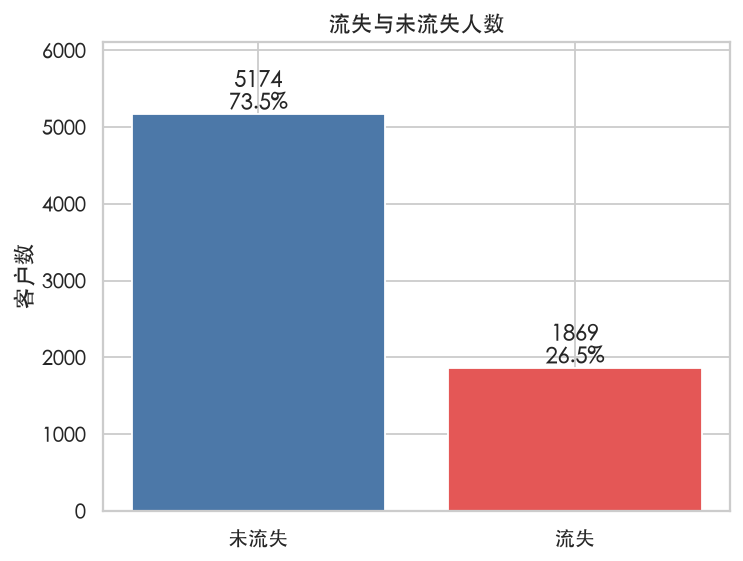

结论：整体流失率 26.5%（流失 1869 / 未流失 5174）。流失客户 ARPU 74.44 元，平均在网 18.0 个月，ARPU×LT = 1338 元。累计费用均值是 1532 元，和 ARPU×LT 不完全相等，因为月费在在网期间会变。


In [4]:
section("3. 整体流失")
churned = clean[clean["Churn"] == "Yes"]
stayed = clean[clean["Churn"] == "No"]
arpu = float(churned["MonthlyCharges"].mean())
lt = float(churned["tenure"].mean())
ltv = arpu * lt
churned_total = float(churned["TotalCharges"].mean())
print(f"流失 {len(churned)} 人（{len(churned) / len(clean):.2%}），留存 {len(stayed)} 人（{len(stayed) / len(clean):.2%}）")
print(f"流失客户 ARPU（MonthlyCharges 均值）= {arpu:.2f}")
print(f"流失客户 LT（tenure 均值）= {lt:.2f}")
print(f"流失客户 LTV（ARPU × LT）= {ltv:.2f}")
print(f"对照：流失客户 TotalCharges 均值 = {churned_total:.2f}")

fig, ax = plt.subplots(figsize=(5.6, 4.2), constrained_layout=True)
counts = clean["Churn"].value_counts().reindex(["No", "Yes"])
bars = ax.bar(["未流失", "流失"], counts.values, color=[PALETTE["No"], PALETTE["Yes"]])
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 40, f"{int(value)}\n{value / len(clean):.1%}", ha="center")
ax.set_ylabel("客户数")
ax.set_title("流失与未流失人数")
ax.set_ylim(0, counts.max() * 1.18)
save_fig(fig, "01_churn_overview.png")
note(
    f"整体流失率 {frame_churn:.1%}（流失 {len(churned)} / 未流失 {len(stayed)}）。"
    f"流失客户 ARPU {arpu:.2f} 元，平均在网 {lt:.1f} 个月，ARPU×LT = {ltv:.0f} 元。"
    f"累计费用均值是 {churned_total:.0f} 元，和 ARPU×LT 不完全相等，因为月费在在网期间会变。"
)


## 4. 分维度看谁更容易走

左图按 `Churn` 着色看人数，右图看流失率。右图红色表示高于整体流失率。增值服务在比较「开通后是否下降」时，只比较 Yes 和 No，不把「没有网络」算进没开通。



4. 分维度流失率


[图] outputs/figures/02_user_attributes.png


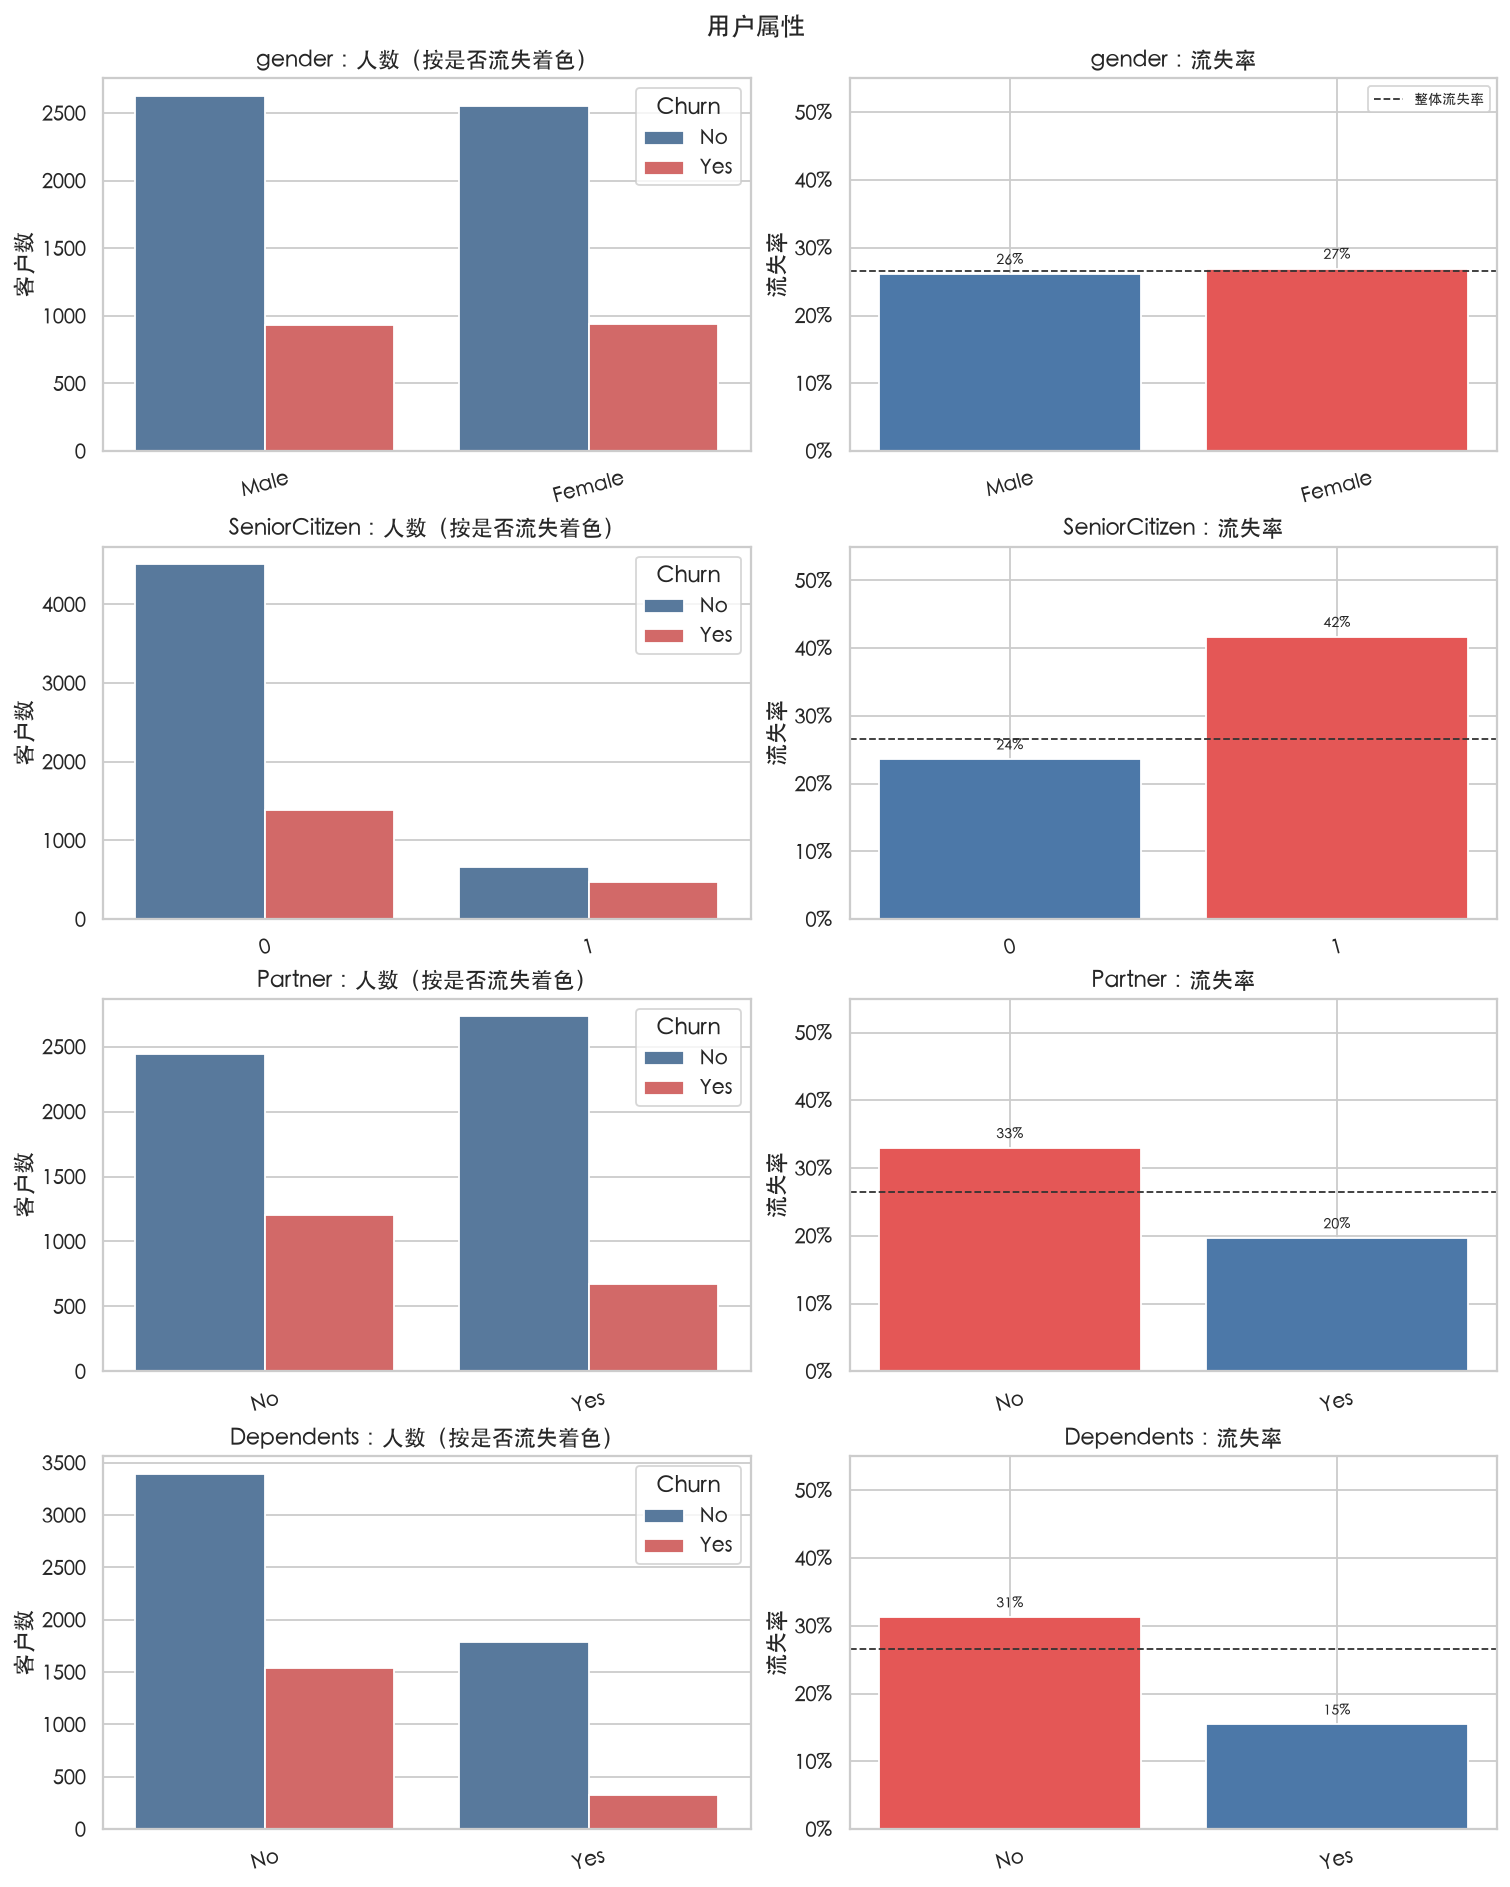

结论：用户属性流失率：gender：Female 26.9%（3488人），Male 26.2%（3555人）；SeniorCitizen：1 41.7%（1142人），0 23.6%（5901人）；Partner：No 33.0%（3641人），Yes 19.7%（3402人）；Dependents：No 31.3%（4933人），Yes 15.5%（2110人）


[图] outputs/figures/03_phone.png


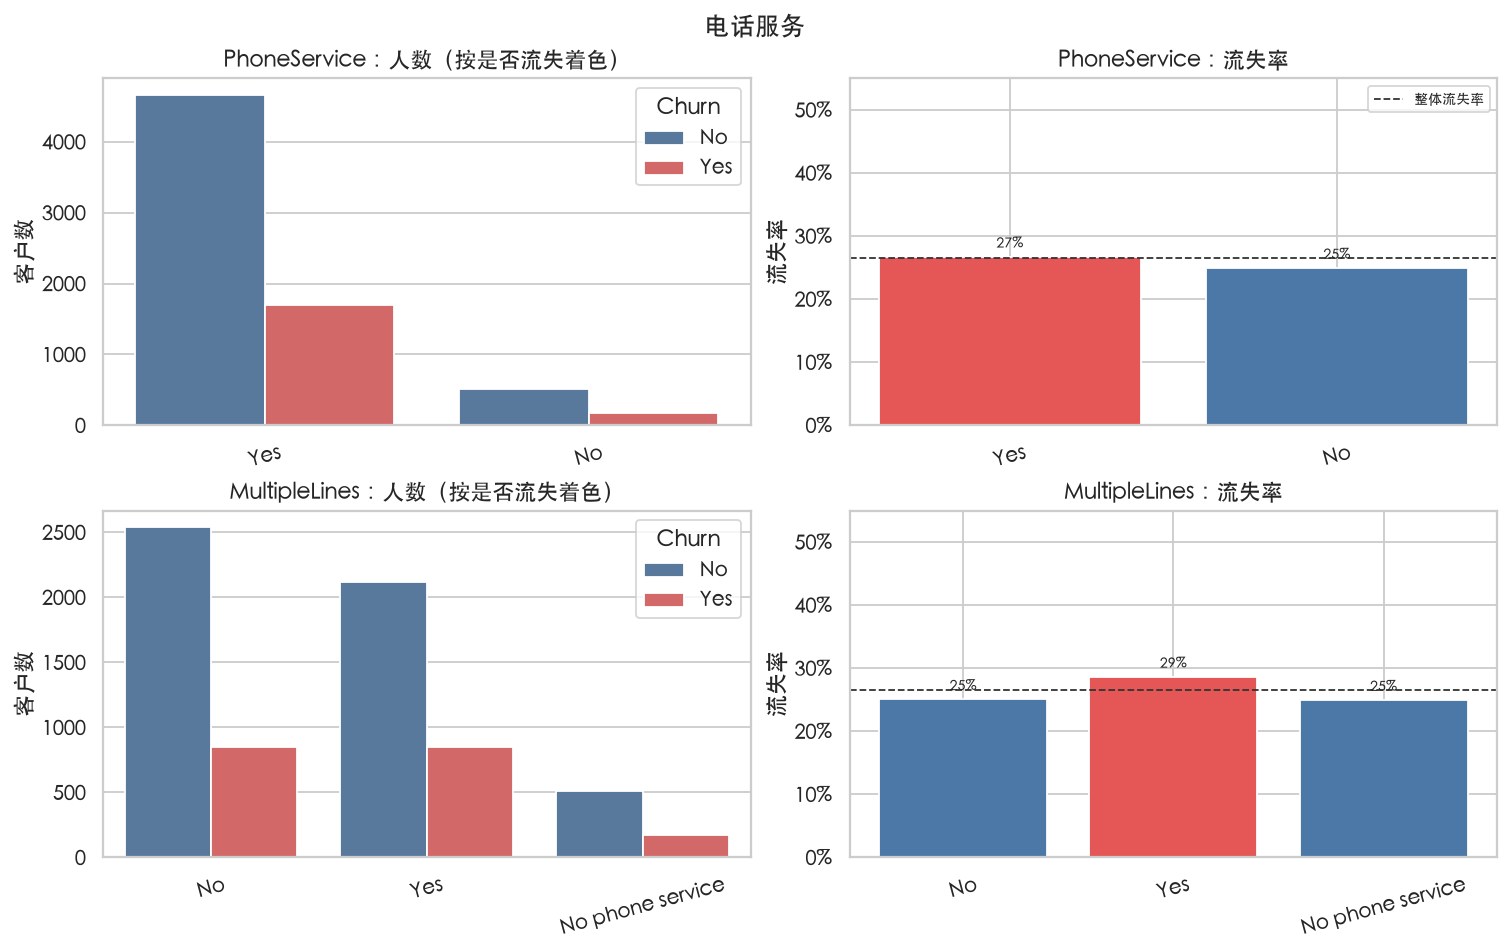

结论：电话：PhoneService：Yes 26.7%（6361人），No 24.9%（682人）；MultipleLines：Yes 28.6%（2971人），No 25.0%（3390人），No phone service 24.9%（682人）
[图] outputs/figures/04_internet.png


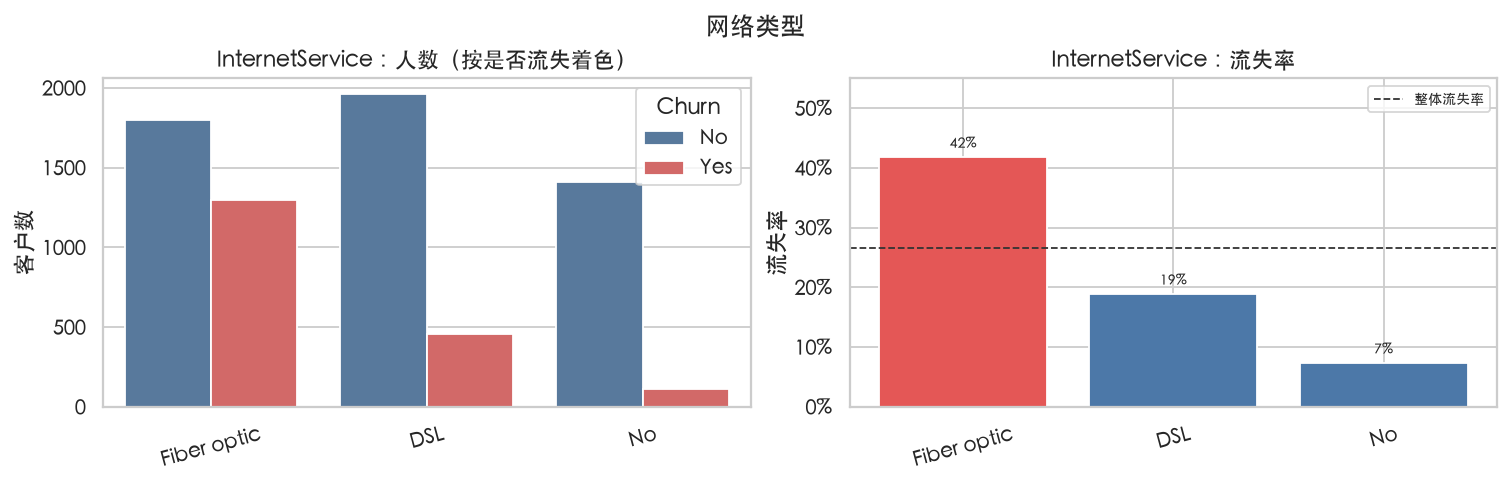

结论：网络类型：Fiber optic 41.9%（3096人），DSL 19.0%（2421人），No 7.4%（1526人）


[图] outputs/figures/05_addons.png


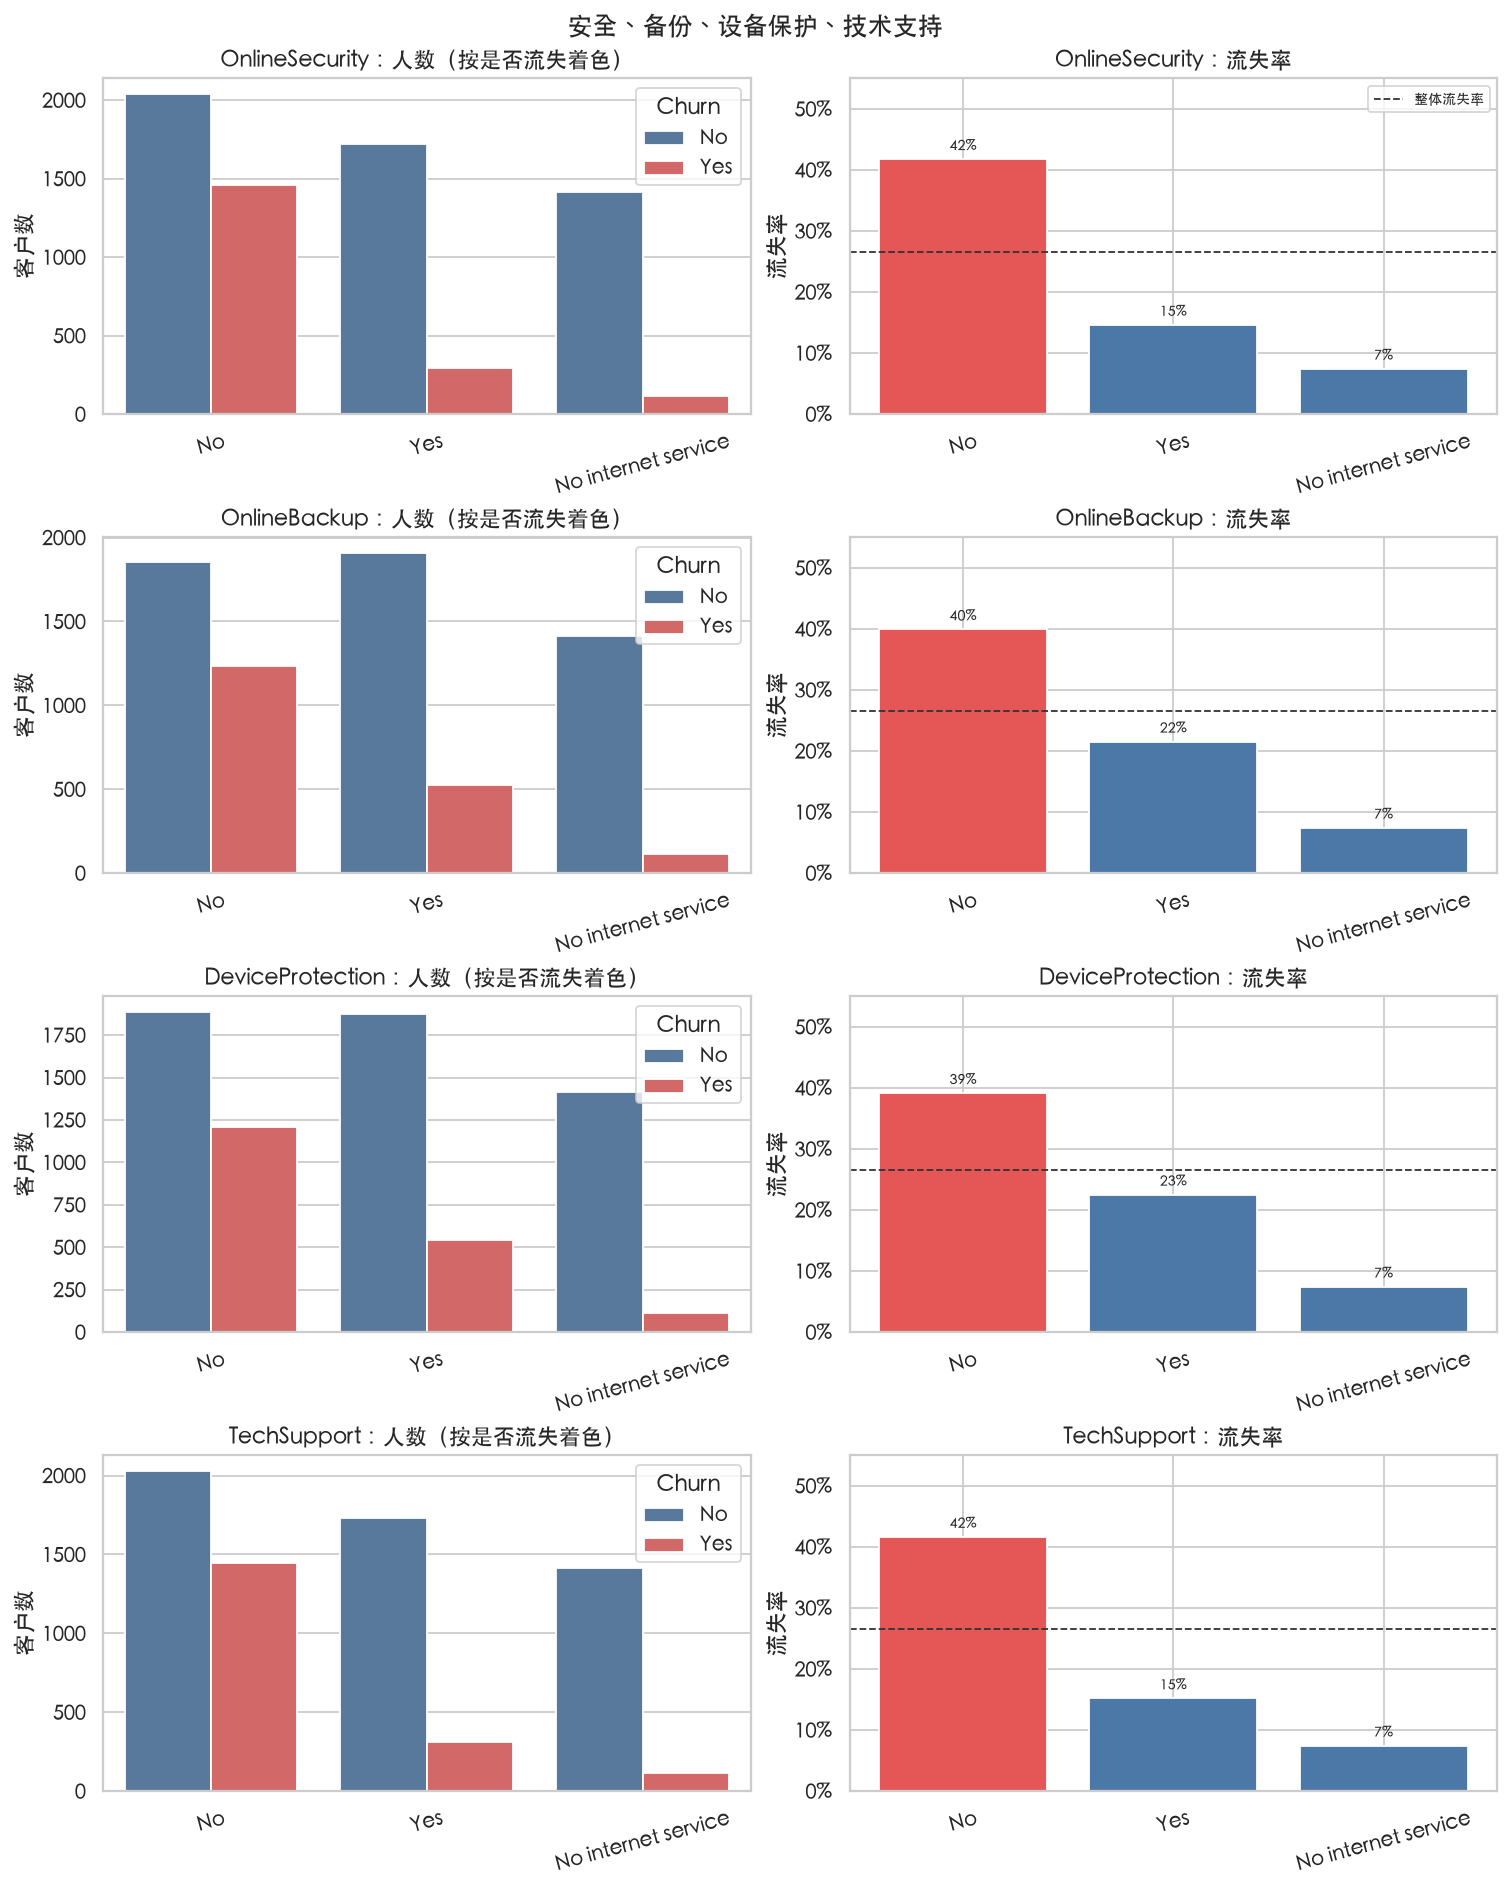

结论：增值服务：OnlineSecurity（只比较开通/未开通）：No 41.8%（3498人），Yes 14.6%（2019人）；OnlineBackup（只比较开通/未开通）：No 39.9%（3088人），Yes 21.5%（2429人）；DeviceProtection（只比较开通/未开通）：No 39.1%（3095人），Yes 22.5%（2422人）；TechSupport（只比较开通/未开通）：No 41.6%（3473人），Yes 15.2%（2044人）


[图] outputs/figures/06_streaming.png


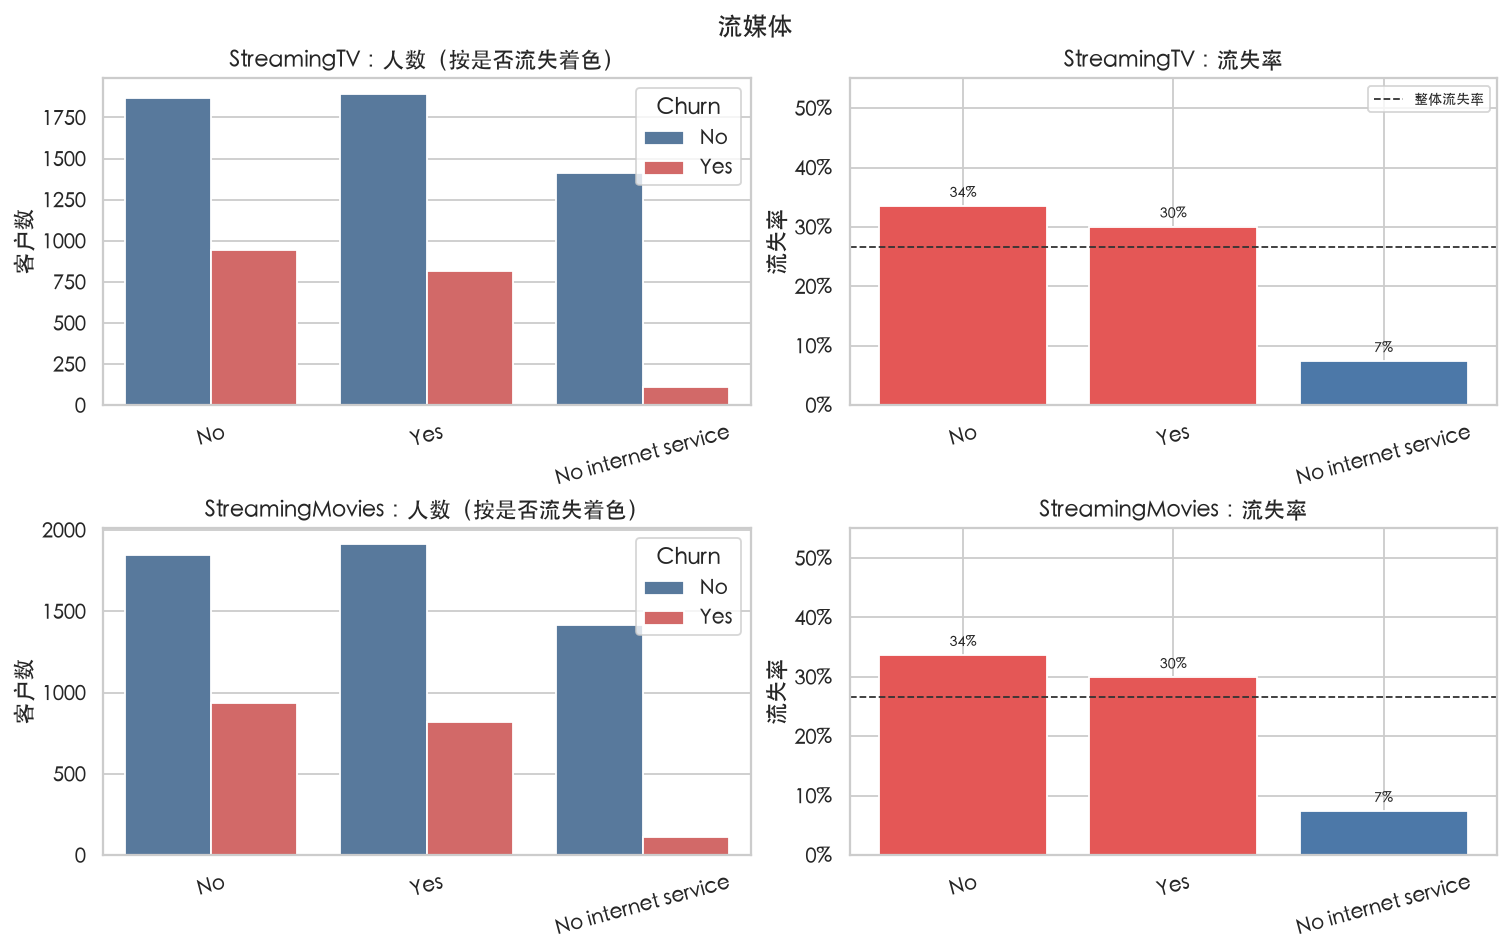

结论：流媒体：StreamingTV（只比较开通/未开通）：No 33.5%（2810人），Yes 30.1%（2707人）；StreamingMovies（只比较开通/未开通）：No 33.7%（2785人），Yes 29.9%（2732人）


[图] outputs/figures/07_contract_payment.png


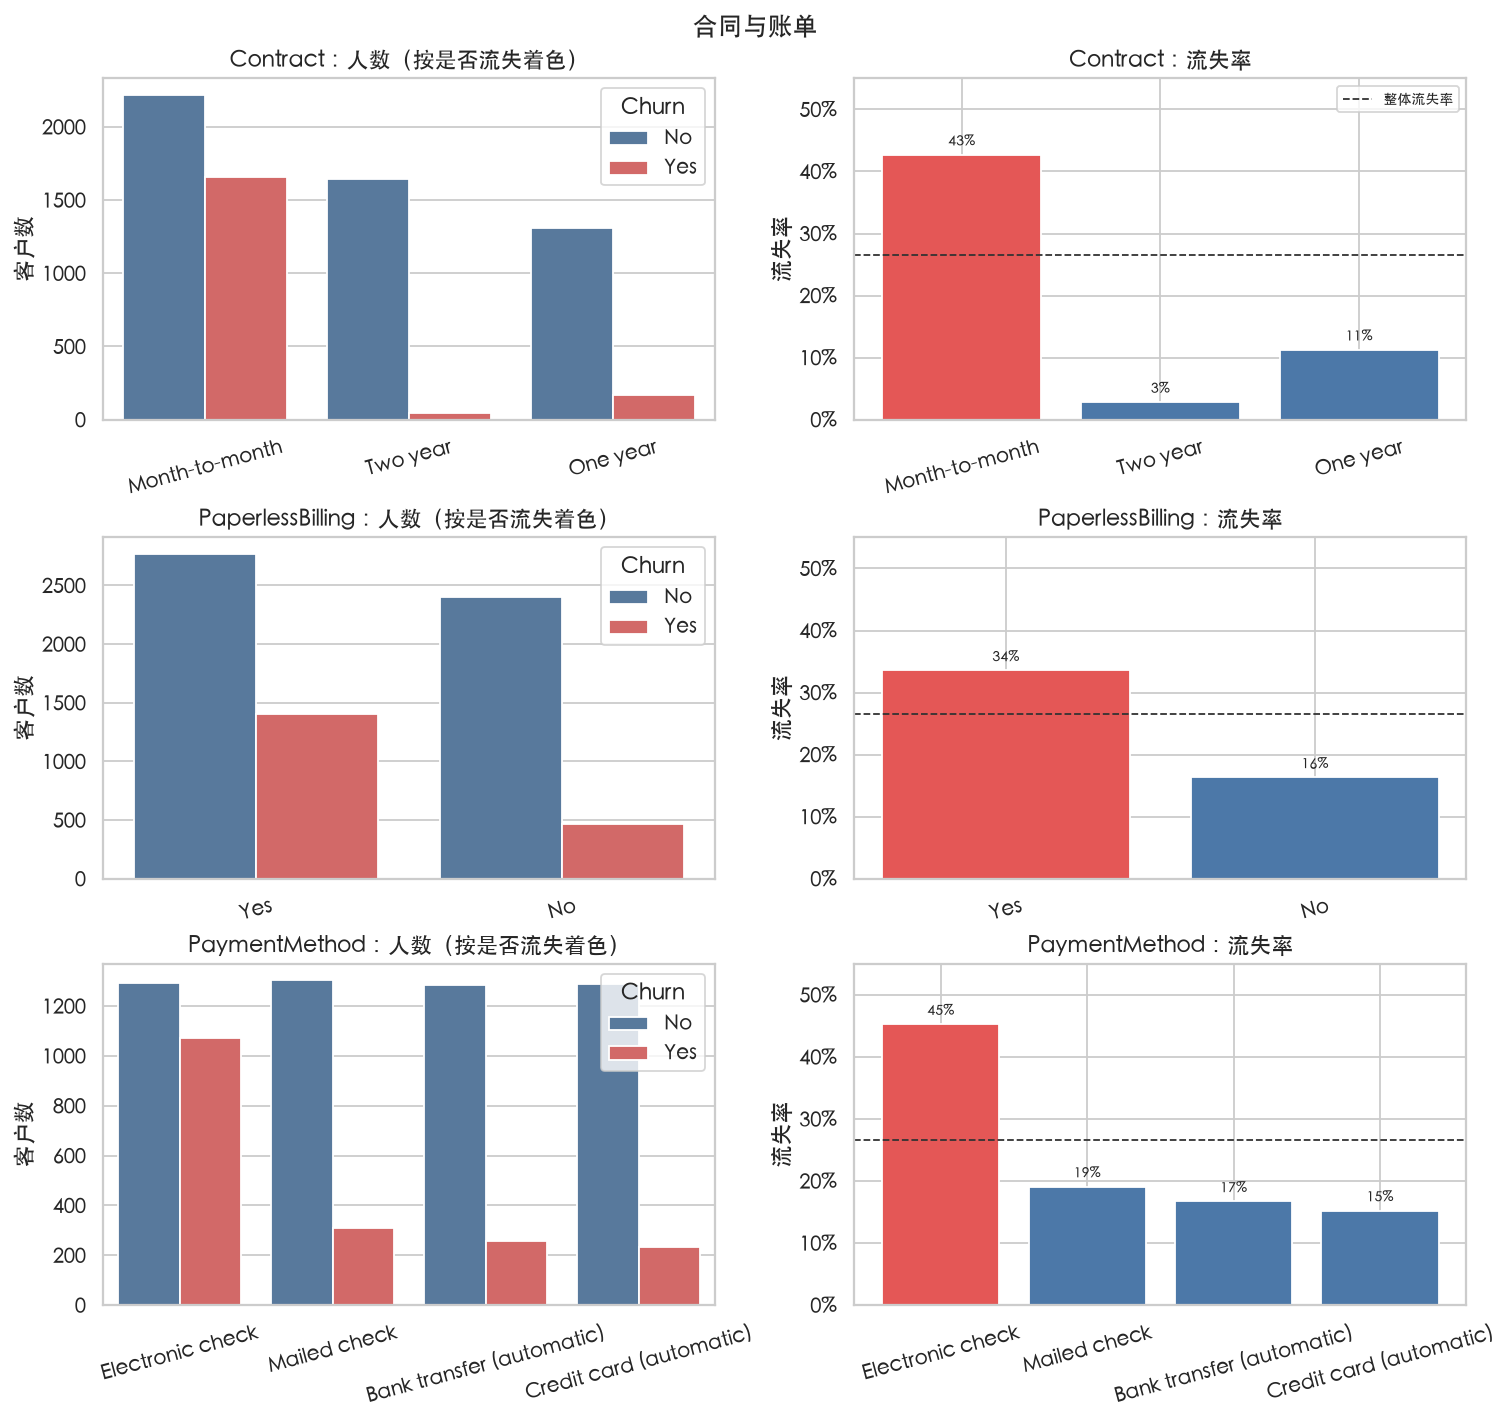

结论：合同与账单：Contract：Month-to-month 42.7%（3875人），One year 11.3%（1473人），Two year 2.8%（1695人）；PaperlessBilling：Yes 33.6%（4171人），No 16.3%（2872人）；PaymentMethod：Electronic check 45.3%（2365人），Mailed check 19.1%（1612人），Bank transfer (automatic) 16.7%（1544人），Credit card (automatic) 15.2%（1522人）


[图] outputs/figures/08_numeric_distribution.png


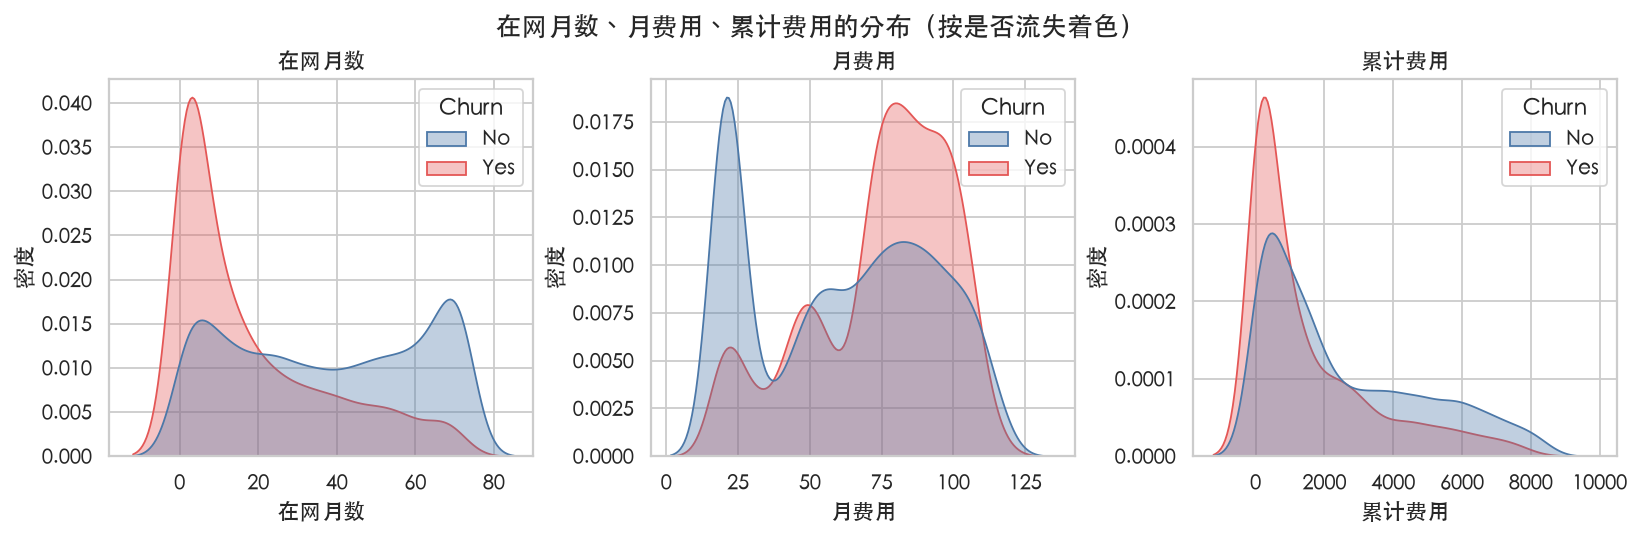

按在网时长的流失率：
               n  churned  churn_rate
tenure_bin                           
0-6个月       1481      784    0.529372
7-12个月       705      253    0.358865
13-20个月      692      214    0.309249
21-36个月     1164      260    0.223368
37-72个月     3001      358    0.119294
按月费四分位的流失率：
                    n  churned  churn_rate
charge_bin                                
(70.35, 89.85]   1757      659    0.375071
(89.85, 118.75]  1758      578    0.328783
(35.5, 70.35]    1766      434    0.245753
(18.249, 35.5]   1762      198    0.112372
结论：在网时长分段流失率：0-6个月 52.9%，7-12个月 35.9%，13-20个月 30.9%，21-36个月 22.3%，37-72个月 11.9%
结论：月费四分位流失率：(70.35, 89.85] 37.5%，(89.85, 118.75] 32.9%，(35.5, 70.35] 24.6%，(18.249, 35.5] 11.2%
[图] outputs/figures/09_tenure_vs_monthly.png


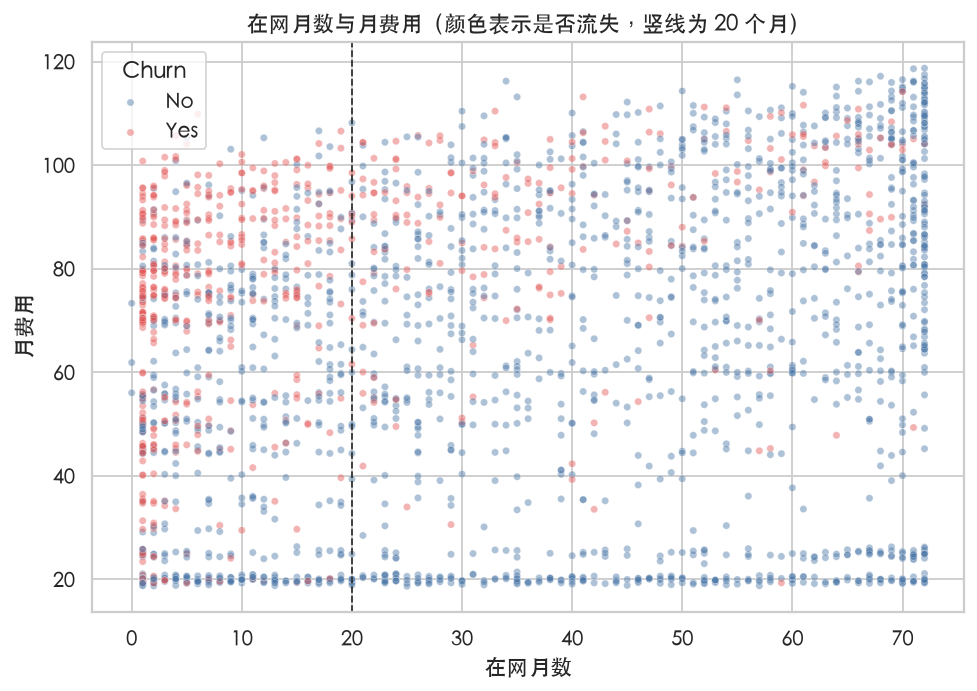

[图] outputs/figures/10_tenure_charge_heatmap.png


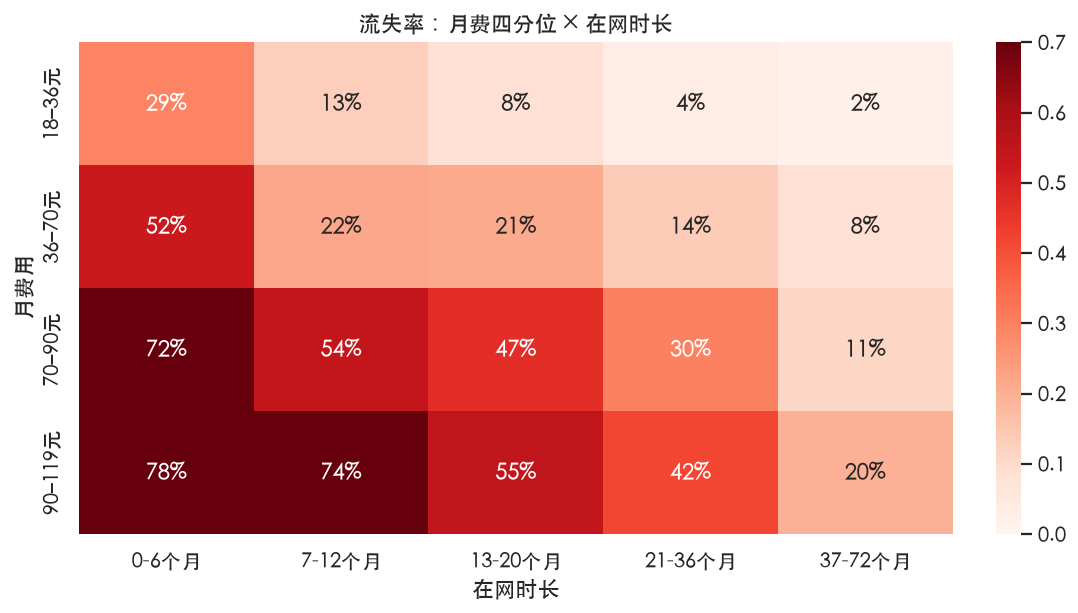

格子人数：
tenure_bin       0-6个月  7-12个月  13-20个月  21-36个月  37-72个月
charge_bin                                               
(18.249, 35.5]     451     201      193      278      639
(35.5, 70.35]      501     203      180      295      587
(70.35, 89.85]     409     201      192      313      642
(89.85, 118.75]    120     100      127      278     1133
月费中位数 70.35，75 分位 89.85
在网超过 20 个月且月费≥75分位：1421 人，流失率 24.07%
在网超过 20 个月且月费<中位数：1795 人，流失率 6.24%
在网不超过 20 个月：2878 人，流失率 43.47%
结论：在网超过 20 个月后，月费不低于 75 分位（89.85 元）的客户流失率是 24.1%（1421人），月费低于中位数的客户是 6.2%（1795人）。高月费在长在网客户里仍然更高，但两组都低于在网不超过 20 个月的 43.5%。


In [5]:
section("4. 分维度流失率")


def describe_levels(frame: pd.DataFrame, col: str) -> str:
    rates = churn_rate_table(frame, col)
    parts = [f"{idx} {row.churn_rate:.1%}（{int(row.n)}人）" for idx, row in rates.iterrows()]
    return "，".join(parts)


plot_by_churn(clean, ["gender", "SeniorCitizen", "Partner", "Dependents"], "用户属性", "02_user_attributes.png")
note("用户属性流失率：" + "；".join(f"{c}：{describe_levels(clean, c)}" for c in ["gender", "SeniorCitizen", "Partner", "Dependents"]))

plot_by_churn(clean, ["PhoneService", "MultipleLines"], "电话服务", "03_phone.png")
note("电话：" + "；".join(f"{c}：{describe_levels(clean, c)}" for c in ["PhoneService", "MultipleLines"]))

plot_by_churn(clean, ["InternetService"], "网络类型", "04_internet.png")
note("网络类型：" + describe_levels(clean, "InternetService"))

addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
plot_by_churn(clean, addon_cols, "安全、备份、设备保护、技术支持", "05_addons.png")
addon_bits = []
for col in addon_cols:
    sub = clean[clean[col].isin(["Yes", "No"])]
    addon_bits.append(f"{col}（只比较开通/未开通）：{describe_levels(sub, col)}")
note("增值服务：" + "；".join(addon_bits))

stream_cols = ["StreamingTV", "StreamingMovies"]
plot_by_churn(clean, stream_cols, "流媒体", "06_streaming.png")
stream_bits = []
for col in stream_cols:
    sub = clean[clean[col].isin(["Yes", "No"])]
    stream_bits.append(f"{col}（只比较开通/未开通）：{describe_levels(sub, col)}")
note("流媒体：" + "；".join(stream_bits))

plot_by_churn(
    clean,
    ["Contract", "PaperlessBilling", "PaymentMethod"],
    "合同与账单",
    "07_contract_payment.png",
)
note(
    "合同与账单："
    + "；".join(f"{c}：{describe_levels(clean, c)}" for c in ["Contract", "PaperlessBilling", "PaymentMethod"])
)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.0), constrained_layout=True)
for ax, col, label in zip(
    axes,
    ["tenure", "MonthlyCharges", "TotalCharges"],
    ["在网月数", "月费用", "累计费用"],
):
    sns.kdeplot(data=clean, x=col, hue="Churn", hue_order=["No", "Yes"], palette=PALETTE, common_norm=False, ax=ax, fill=True, alpha=0.35)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("密度")
fig.suptitle("在网月数、月费用、累计费用的分布（按是否流失着色）")
save_fig(fig, "08_numeric_distribution.png")

tenure_bins = pd.cut(
    clean["tenure"],
    bins=[-0.1, 6, 12, 20, 36, 72],
    labels=["0-6个月", "7-12个月", "13-20个月", "21-36个月", "37-72个月"],
)
tenure_rates = churn_rate_table(clean.assign(tenure_bin=tenure_bins), "tenure_bin")
print("按在网时长的流失率：")
print(tenure_rates.to_string())
charge_bins = pd.qcut(clean["MonthlyCharges"], 4, duplicates="drop")
charge_rates = churn_rate_table(clean.assign(charge_bin=charge_bins), "charge_bin")
print("按月费四分位的流失率：")
print(charge_rates.to_string())
note("在网时长分段流失率：" + "，".join(f"{idx} {row.churn_rate:.1%}" for idx, row in tenure_rates.iterrows()))
note("月费四分位流失率：" + "，".join(f"{idx} {row.churn_rate:.1%}" for idx, row in charge_rates.iterrows()))

fig, ax = plt.subplots(figsize=(7.4, 5.2), constrained_layout=True)
sample = clean.sample(n=min(2500, len(clean)), random_state=RANDOM_STATE)
sns.scatterplot(
    data=sample,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    hue_order=["No", "Yes"],
    palette=PALETTE,
    alpha=0.45,
    s=16,
    ax=ax,
)
ax.axvline(20, color="#333333", ls="--", lw=1)
ax.set_title("在网月数与月费用（颜色表示是否流失，竖线为 20 个月）")
ax.set_xlabel("在网月数")
ax.set_ylabel("月费用")
save_fig(fig, "09_tenure_vs_monthly.png")

heat = clean.assign(tenure_bin=tenure_bins, charge_bin=charge_bins)
heat_rate = heat.pivot_table(index="charge_bin", columns="tenure_bin", values="Churn", aggfunc=lambda s: (s == "Yes").mean())
heat_n = heat.pivot_table(index="charge_bin", columns="tenure_bin", values="Churn", aggfunc="size")
heat_rate_plot = heat_rate.copy()
heat_n_plot = heat_n.copy()
heat_rate_plot.index = [f"{iv.left:.0f}–{iv.right:.0f}元" for iv in heat_rate_plot.index]
heat_n_plot.index = heat_rate_plot.index
fig, ax = plt.subplots(figsize=(8.2, 4.6), constrained_layout=True)
sns.heatmap(heat_rate_plot, annot=True, fmt=".0%", cmap="Reds", ax=ax, vmin=0, vmax=0.7)
ax.set_title("流失率：月费四分位 × 在网时长")
ax.set_xlabel("在网时长")
ax.set_ylabel("月费用")
save_fig(fig, "10_tenure_charge_heatmap.png")
print("格子人数：")
print(heat_n.to_string())

long_tenure = clean[clean["tenure"] > 20]
charge_median = float(clean["MonthlyCharges"].median())
charge_p75 = float(clean["MonthlyCharges"].quantile(0.75))
long_high = long_tenure[long_tenure["MonthlyCharges"] >= charge_p75]
long_low = long_tenure[long_tenure["MonthlyCharges"] < charge_median]
print(f"月费中位数 {charge_median:.2f}，75 分位 {charge_p75:.2f}")
print(f"在网超过 20 个月且月费≥75分位：{len(long_high)} 人，流失率 {rate_of(long_high):.2%}")
print(f"在网超过 20 个月且月费<中位数：{len(long_low)} 人，流失率 {rate_of(long_low):.2%}")
print(f"在网不超过 20 个月：{int((clean['tenure'] <= 20).sum())} 人，流失率 {rate_of(clean[clean['tenure'] <= 20]):.2%}")
note(
    f"在网超过 20 个月后，月费不低于 75 分位（{charge_p75:.2f} 元）的客户流失率是 {rate_of(long_high):.1%}（{len(long_high)}人），"
    f"月费低于中位数的客户是 {rate_of(long_low):.1%}（{len(long_low)}人）。"
    f"高月费在长在网客户里仍然更高，但两组都低于在网不超过 20 个月的 {rate_of(clean[clean['tenure'] <= 20]):.1%}。"
)


## 5. 运营画像

下面的判断都来自上面的流失率，不沿用课件原文。三个动作各自对应一个算得出来的人群。


In [6]:
section("5. 画像与运营动作")
gender_rates = churn_rate_table(clean, "gender")
senior_rates = churn_rate_table(clean, "SeniorCitizen")
partner_rates = churn_rate_table(clean, "Partner")
dependents_rates = churn_rate_table(clean, "Dependents")
phone_rates = churn_rate_table(clean, "PhoneService")
multi_sub = clean[clean["MultipleLines"].isin(["Yes", "No"])]
multi_rates = churn_rate_table(multi_sub, "MultipleLines")
internet_rates = churn_rate_table(clean, "InternetService")
contract_rates = churn_rate_table(clean, "Contract")
paper_rates = churn_rate_table(clean, "PaperlessBilling")
pay_rates = churn_rate_table(clean, "PaymentMethod")


def gap(table: pd.DataFrame) -> float:
    return float(table["churn_rate"].max() - table["churn_rate"].min())


portrait_lines = []
portrait_lines.append(
    f"性别差别很小：{describe_levels(clean, 'gender')}，两端只差 {gap(gender_rates):.1%}。"
)
portrait_lines.append(
    f"老年人流失率更高：{describe_levels(clean, 'SeniorCitizen')}。"
    f"没有伴侣、没有家属的客户也更高：伴侣 {describe_levels(clean, 'Partner')}；家属 {describe_levels(clean, 'Dependents')}。"
)
portrait_lines.append(
    f"是否开通电话的差别不大（{describe_levels(clean, 'PhoneService')}，相差 {gap(phone_rates):.1%}）。"
    f"在已有电话的客户里，多线和单线相差 {gap(multi_rates):.1%}（{describe_levels(multi_sub, 'MultipleLines')}）。"
    "电话本身不是主要分界。"
)
portrait_lines.append(f"光纤高于 DSL，也高于没有网络：{describe_levels(clean, 'InternetService')}。")

addon_sentences = []
for col, label in zip(addon_cols, ["在线安全", "在线备份", "设备保护", "技术支持"]):
    sub = clean[clean[col].isin(["Yes", "No"])]
    rates = churn_rate_table(sub, col)
    direction = "更低" if rates.loc["Yes", "churn_rate"] < rates.loc["No", "churn_rate"] else "更高"
    addon_sentences.append(
        f"{label}开通后流失率{direction}（开通 {rates.loc['Yes', 'churn_rate']:.1%}，未开通 {rates.loc['No', 'churn_rate']:.1%}）"
    )
portrait_lines.append("有网络的客户里，" + "；".join(addon_sentences) + "。")

stream_sentences = []
stream_gaps = []
for col, label in zip(stream_cols, ["流媒体电视", "流媒体电影"]):
    sub = clean[clean[col].isin(["Yes", "No"])]
    rates = churn_rate_table(sub, col)
    direction = "更低" if rates.loc["Yes", "churn_rate"] < rates.loc["No", "churn_rate"] else "更高"
    stream_gaps.append(abs(float(rates.loc["Yes", "churn_rate"] - rates.loc["No", "churn_rate"])))
    stream_sentences.append(
        f"{label}开通后流失率{direction}（开通 {rates.loc['Yes', 'churn_rate']:.1%}，未开通 {rates.loc['No', 'churn_rate']:.1%}）"
    )
portrait_lines.append(
    "流媒体差别很小："
    + "；".join(stream_sentences)
    + f"。两边只差约 {max(stream_gaps):.1%}，远小于在线安全和技术支持大约 26 个百分点的差距，不作为主要挽留手段。"
)
portrait_lines.append(
    f"月付合同、无纸化账单、电子支票更高：合同 {describe_levels(clean, 'Contract')}；"
    f"无纸化 {describe_levels(clean, 'PaperlessBilling')}；付款方式 {describe_levels(clean, 'PaymentMethod')}。"
)
within_tenure_increases = all(
    heat_rate[col].is_monotonic_increasing for col in heat_rate.columns
)
lowest_q = charge_rates.sort_index().iloc[0]
highest_band = charge_rates.iloc[0]
portrait_lines.append(
    "在网越短，流失率越高："
    + "，".join(f"{idx} {row.churn_rate:.1%}" for idx, row in tenure_rates.sort_index().iterrows())
    + "。"
    + (
        "把在网时长固定以后，月费档越高，流失率越高。"
        if within_tenure_increases
        else "同一个在网分段里，月费和流失率不是每档都递增。"
    )
    + f"不分时长时，流失率最高的月费档是 {highest_band.name}（{highest_band.churn_rate:.1%}），"
    f"最低月费档是 {lowest_q.name}（{lowest_q.churn_rate:.1%}）；最高月费档没有继续升高，因为里面有很多在网已久的客户。"
    + NOTES[-1]
)

m2m_new = clean[(clean["Contract"] == "Month-to-month") & (clean["tenure"] < 6)]
fiber_no_support = clean[(clean["InternetService"] == "Fiber optic") & (clean["TechSupport"] == "No")]
high_bill_loyal = clean[(clean["tenure"] > 20) & (clean["MonthlyCharges"] >= charge_p75)]

actions = [
    (
        "月付且在网不足 6 个月",
        m2m_new,
        "把年付或两年合同的差价讲清楚，优先推一年约。这一组在网短、合同又是月付，离开成本最低。",
    ),
    (
        "光纤且没有技术支持",
        fiber_no_support,
        "做一次开通体验回访，并给出技术支持试用。光纤流失率高，没买技术支持的人更高。",
    ),
    (
        f"在网超过 20 个月且月费不低于 {charge_p75:.0f} 元",
        high_bill_loyal,
        "做套餐复核，看高月费是否还匹配实际用量。他们流失率不是全库最高，但在网已经较长、月费高，挽留价值大。",
    ),
]
print("\n".join(portrait_lines))
print("\n运营动作：")
action_lines = []
for name, seg, action in actions:
    line = f"{name}：{len(seg)} 人，流失率 {rate_of(seg):.1%}（整体 {frame_churn:.1%}）。{action}"
    action_lines.append(line)
    print(line)

profile_text = []
profile_text.append("电信客户流失画像")
profile_text.append("")
profile_text.append(
    f"样本 {len(clean)} 人，流失 {len(churned)} 人（{frame_churn:.1%}），未流失 {len(stayed)} 人。"
    f"流失客户 ARPU {arpu:.2f} 元，平均在网 {lt:.1f} 个月，ARPU×LT = {ltv:.0f} 元。"
)
profile_text.append("")
profile_text.append("哪些客户更容易走")
for line in portrait_lines:
    profile_text.append("- " + line)
profile_text.append("")
profile_text.append("给运营的三个动作")
for i, line in enumerate(action_lines, start=1):
    profile_text.append(f"{i}. {line}")
profile_path = OUT / "churn_profile.txt"
profile_path.write_text("\n".join(profile_text) + "\n", encoding="utf-8")
print(f"\n已写入 {profile_path.relative_to(ROOT)}")



5. 画像与运营动作
性别差别很小：Female 26.9%（3488人），Male 26.2%（3555人），两端只差 0.8%。
老年人流失率更高：1 41.7%（1142人），0 23.6%（5901人）。没有伴侣、没有家属的客户也更高：伴侣 No 33.0%（3641人），Yes 19.7%（3402人）；家属 No 31.3%（4933人），Yes 15.5%（2110人）。
是否开通电话的差别不大（Yes 26.7%（6361人），No 24.9%（682人），相差 1.8%）。在已有电话的客户里，多线和单线相差 3.6%（Yes 28.6%（2971人），No 25.0%（3390人））。电话本身不是主要分界。
光纤高于 DSL，也高于没有网络：Fiber optic 41.9%（3096人），DSL 19.0%（2421人），No 7.4%（1526人）。
有网络的客户里，在线安全开通后流失率更低（开通 14.6%，未开通 41.8%）；在线备份开通后流失率更低（开通 21.5%，未开通 39.9%）；设备保护开通后流失率更低（开通 22.5%，未开通 39.1%）；技术支持开通后流失率更低（开通 15.2%，未开通 41.6%）。
流媒体差别很小：流媒体电视开通后流失率更低（开通 30.1%，未开通 33.5%）；流媒体电影开通后流失率更低（开通 29.9%，未开通 33.7%）。两边只差约 3.7%，远小于在线安全和技术支持大约 26 个百分点的差距，不作为主要挽留手段。
月付合同、无纸化账单、电子支票更高：合同 Month-to-month 42.7%（3875人），One year 11.3%（1473人），Two year 2.8%（1695人）；无纸化 Yes 33.6%（4171人），No 16.3%（2872人）；付款方式 Electronic check 45.3%（2365人），Mailed check 19.1%（1612人），Bank transfer (automatic) 16.7%（1544人），Credit card (automatic) 15.2%（1522人）。
在网越短，流失率越高：0-6个月 52.9%，7-12个月 35.9%，13-20个月 30.9%，21-36个月 22.3%，37-72个月 11.

## 6. 先切分

分层抽样，60% 训练、20% 验证、20% 留出。留出集的 `Churn` 从这一节起不再参与训练和定门槛。三份 `customerID` 不交叉。

清洗发生在切分之前，因为「tenure 为 0 则累计费用填 0」是这一行自己的规则，不是从别的客户身上估计出来的。


In [7]:
section("6. 切分")
rest, holdout = train_test_split(
    clean,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=clean["Churn"],
)
train, valid = train_test_split(
    rest,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=rest["Churn"],
)
train = train.reset_index(drop=True)
valid = valid.reset_index(drop=True)
holdout = holdout.reset_index(drop=True)

id_sets = {
    "train": set(train["customerID"]),
    "valid": set(valid["customerID"]),
    "holdout": set(holdout["customerID"]),
}
assert id_sets["train"].isdisjoint(id_sets["valid"])
assert id_sets["train"].isdisjoint(id_sets["holdout"])
assert id_sets["valid"].isdisjoint(id_sets["holdout"])
assert sum(len(s) for s in id_sets.values()) == len(clean)

split_rows = []
for name, part in [("train", train), ("valid", valid), ("holdout", holdout)]:
    split_rows.append(
        {
            "split": name,
            "n": len(part),
            "share": len(part) / len(clean),
            "churn_rate": rate_of(part),
            "churned": int((part["Churn"] == "Yes").sum()),
        }
    )
split_summary = pd.DataFrame(split_rows)
print(split_summary.to_string(index=False))
pd.concat(
    [
        train.assign(split="train"),
        valid.assign(split="valid"),
        holdout.assign(split="holdout"),
    ]
)[["customerID", "split"]].to_csv(OUT / "split_ids.csv", index=False)

y_train = (train["Churn"] == "Yes").astype(int).to_numpy()
y_valid = (valid["Churn"] == "Yes").astype(int).to_numpy()
y_holdout = (holdout["Churn"] == "Yes").astype(int).to_numpy()



6. 切分
  split    n    share  churn_rate  churned
  train 4225 0.599886    0.265325     1121
  valid 1409 0.200057    0.265436      374
holdout 1409 0.200057    0.265436      374


## 7. 准备特征

`Contract` 按月付 < 一年 < 两年编成 0、1、2。其余类别没有顺序，留给 LightGBM 按类别列处理；逻辑回归使用独热编码。编码时出现过的类别只从训练集收集，再套到验证集和留出集。树模型不把数值缩放到 0–1。`InternetService` 保留。


In [8]:
section("7. 特征")
X_train, cat_levels = build_lgb_frame(train)
X_valid, _ = build_lgb_frame(valid, cat_levels)
X_holdout, _ = build_lgb_frame(holdout, cat_levels)
for frame in (X_train, X_valid, X_holdout):
    assert "customerID" not in frame.columns
    assert "Churn" not in frame.columns
print("LightGBM 特征：", list(X_train.columns))
print("训练集锁定的类别水平：")
for col, levels in cat_levels.items():
    print(f"  {col}: {levels}")

LR_NUM = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
LR_CAT = ["Contract", *CAT_COLS]
lr_train = train[LR_NUM + LR_CAT]
lr_valid = valid[LR_NUM + LR_CAT]
lr_holdout = holdout[LR_NUM + LR_CAT]



7. 特征
LightGBM 特征： ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'PaymentMethod']
训练集锁定的类别水平：
  gender: ['Female', 'Male']
  Partner: ['No', 'Yes']
  Dependents: ['No', 'Yes']
  PhoneService: ['No', 'Yes']
  MultipleLines: ['No', 'No phone service', 'Yes']
  InternetService: ['DSL', 'Fiber optic', 'No']
  OnlineSecurity: ['No', 'No internet service', 'Yes']
  OnlineBackup: ['No', 'No internet service', 'Yes']
  DeviceProtection: ['No', 'No internet service', 'Yes']
  TechSupport: ['No', 'No internet service', 'Yes']
  StreamingTV: ['No', 'No internet service', 'Yes']
  StreamingMovies: ['No', 'No internet service', 'Yes']
  PaperlessBilling: ['No', 'Yes']
  PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Ma

## 8–9. 类别权重、逻辑回归基线和 LightGBM

不在切分前做全表过采样。LightGBM 的 `scale_pos_weight` 等于训练集里未流失人数 / 流失人数。
逻辑回归回答「月付比两年合同高出多少风险」，解释模型不放 `TotalCharges`，因为它和在网月数×月费几乎是同一件事。预测用的树模型仍保留原始累计费用。


In [9]:
section("8–9. 训练")
n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)
scale_pos_weight = n_neg / n_pos
print(f"训练集未流失 {n_neg}，流失 {n_pos}，scale_pos_weight = {scale_pos_weight:.4f}")

lr_model = Pipeline(
    [
        (
            "pre",
            ColumnTransformer(
                [
                    ("num", StandardScaler(), LR_NUM),
                    (
                        "cat",
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        LR_CAT,
                    ),
                ]
            ),
        ),
        (
            "clf",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
lr_model.fit(lr_train, y_train)

interpret = train.copy()
interpret["y"] = y_train
interpret["security_yes"] = yes_flag(interpret["OnlineSecurity"])
interpret["backup_yes"] = yes_flag(interpret["OnlineBackup"])
interpret["protect_yes"] = yes_flag(interpret["DeviceProtection"])
interpret["support_yes"] = yes_flag(interpret["TechSupport"])
interpret["stream_tv_yes"] = yes_flag(interpret["StreamingTV"])
interpret["stream_movie_yes"] = yes_flag(interpret["StreamingMovies"])
interpret["partner_yes"] = yes_flag(interpret["Partner"])
interpret["dependents_yes"] = yes_flag(interpret["Dependents"])
interpret["paperless_yes"] = yes_flag(interpret["PaperlessBilling"])
interpret["phone_yes"] = yes_flag(interpret["PhoneService"])
interpret["multi_yes"] = yes_flag(interpret["MultipleLines"])
formula = (
    "y ~ C(Contract, Treatment(reference='Two year'))"
    " + tenure + MonthlyCharges + SeniorCitizen"
    " + C(InternetService, Treatment(reference='DSL'))"
    " + C(gender, Treatment(reference='Male'))"
    " + security_yes + backup_yes + protect_yes + support_yes"
    " + stream_tv_yes + stream_movie_yes"
    " + partner_yes + dependents_yes + paperless_yes + phone_yes + multi_yes"
    " + C(PaymentMethod, Treatment(reference='Credit card (automatic)'))"
)
logit = smf.logit(formula, data=interpret).fit(disp=False)
print(logit.summary().tables[1])
contract_term = "C(Contract, Treatment(reference='Two year'))[T.Month-to-month]"
one_year_term = "C(Contract, Treatment(reference='Two year'))[T.One year]"
or_month = float(np.exp(logit.params[contract_term]))
or_one = float(np.exp(logit.params[one_year_term]))
ci = logit.conf_int().loc[contract_term]
or_ci = (float(np.exp(ci[0])), float(np.exp(ci[1])))
print(
    f"调整后，月付相对两年合同的流失几率比（odds ratio）= {or_month:.2f}，95% 区间 {or_ci[0]:.2f}–{or_ci[1]:.2f}。"
)
print(f"一年合同相对两年合同的几率比 = {or_one:.2f}。")
print("这个几率比来自训练集上的未加权逻辑回归，控制了在网月数、月费、网络类型、增值服务和付款方式。")

raw_month = clean[clean["Contract"] == "Month-to-month"]
raw_two = clean[clean["Contract"] == "Two year"]
p_month = rate_of(raw_month)
p_two = rate_of(raw_two)
raw_or = (p_month / (1 - p_month)) / (p_two / (1 - p_two))
print(
    f"未调整对照：月付流失率 {p_month:.1%}，两年合同 {p_two:.1%}，未调整几率比 {raw_or:.2f}。"
)

lgb_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbosity=-1,
)
lgb_model.fit(X_train, y_train, categorical_feature=CAT_COLS)

tree_frame = pd.DataFrame(
    {
        "合同等级_0月付1一年2两年": train["Contract"].map(CONTRACT_MAP).astype(int),
        "在网月数": train["tenure"].astype(float),
        "月费用": train["MonthlyCharges"].astype(float),
        "老年人": train["SeniorCitizen"].astype(int),
        "光纤": (train["InternetService"] == "Fiber optic").astype(int),
        "技术支持": yes_flag(train["TechSupport"]),
        "在线安全": yes_flag(train["OnlineSecurity"]),
        "无纸化账单": yes_flag(train["PaperlessBilling"]),
        "电子支票": (train["PaymentMethod"] == "Electronic check").astype(int),
        "有伴侣": yes_flag(train["Partner"]),
        "有家属": yes_flag(train["Dependents"]),
    }
)
shallow_tree = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=80,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
shallow_tree.fit(tree_frame, y_train)
tree_text = export_text(shallow_tree, feature_names=list(tree_frame.columns), decimals=1)
(OUT / "shallow_tree_rules.txt").write_text(
    "这棵深度 3 的树只用来给业务讲规则，不上线。\n"
    "合同等级：0=月付，1=一年，2=两年。数值是训练时的划分点。\n\n"
    + tree_text,
    encoding="utf-8",
)
print(tree_text)



8–9. 训练
训练集未流失 3104，流失 1121，scale_pos_weight = 2.7690
                                                                                                    coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                                        -0.2112      1.090     -0.194      0.846      -2.347       1.925
C(Contract, Treatment(reference='Two year'))[T.Month-to-month]                                    1.5389      0.233      6.606      0.000       1.082       1.995
C(Contract, Treatment(reference='Two year'))[T.One year]                                          0.7968      0.235      3.387      0.001       0.336       1.258
C(InternetService, Treatment(reference='DSL'))[T.Fiber optic]                                     2.5793      1.050      2.457      0.0

|--- 合同等级_0月付1一年2两年 <= 0.5
|   |--- 光纤 <= 0.5
|   |   |--- 在网月数 <= 5.5
|   |   |   |--- class: 1
|   |   |--- 在网月数 >  5.5
|   |   |   |--- class: 0
|   |--- 光纤 >  0.5
|   |   |--- 在网月数 <= 15.5
|   |   |   |--- class: 1
|   |   |--- 在网月数 >  15.5
|   |   |   |--- class: 1
|--- 合同等级_0月付1一年2两年 >  0.5
|   |--- 月费用 <= 93.8
|   |   |--- 合同等级_0月付1一年2两年 <= 1.5
|   |   |   |--- class: 0
|   |   |--- 合同等级_0月付1一年2两年 >  1.5
|   |   |   |--- class: 0
|   |--- 月费用 >  93.8
|   |   |--- 在网月数 <= 59.5
|   |   |   |--- class: 0
|   |   |--- 在网月数 >  59.5
|   |   |   |--- class: 0



## 10. 在验证集上验收

全部猜成不流失的准确率大约是 73%，那不是这次要追的数。业务容量按验证集风险最高的 10% 定门槛，留出集不再改这个门槛。



10. 验证集
验证集全部猜成不流失的准确率：73.46%
逻辑回归 @0.5 {"threshold": 0.5, "accuracy": 0.7473385379701917, "precision": 0.5157342657342657, "recall": 0.7887700534759359, "f1": 0.6236786469344608, "roc_auc": 0.8363700948099926, "predicted_positive_rate": 0.40596167494677077, "confusion_matrix": [[758, 277], [79, 295]]}
LightGBM @0.5 {"threshold": 0.5, "accuracy": 0.7572746628814763, "precision": 0.5321285140562249, "recall": 0.7085561497326203, "f1": 0.6077981651376146, "roc_auc": 0.8242230489033557, "predicted_positive_rate": 0.3534421575585522, "confusion_matrix": [[802, 233], [109, 265]]}
验证集按概率从高到低取前 141 人（10.0%）。其中真正流失 73.0%，验证集基线 26.5%，是随机抽同样人数的 2.75 倍（高出 1.75 倍）。
锁定的概率门槛 = 0.863337。留出集只使用这个数。
LightGBM @门槛 {"threshold": 0.8633370141260566, "accuracy": 0.7806955287437899, "precision": 0.7304964539007093, "recall": 0.27540106951871657, "f1": 0.4, "roc_auc": 0.8242230489033557, "predicted_positive_rate": 0.10007097232079488, "confusion_matrix": [[997, 38], [271, 103]]}
[图] outputs/figures/11_roc_va

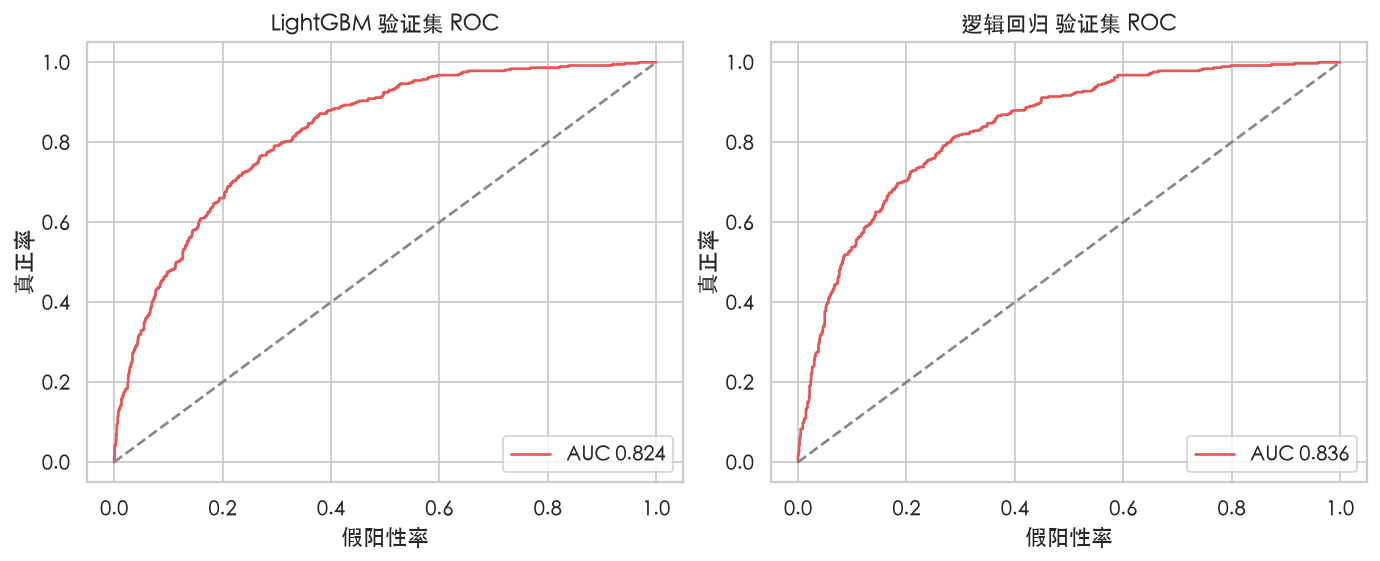

[图] outputs/figures/12_confusion_matrix.png


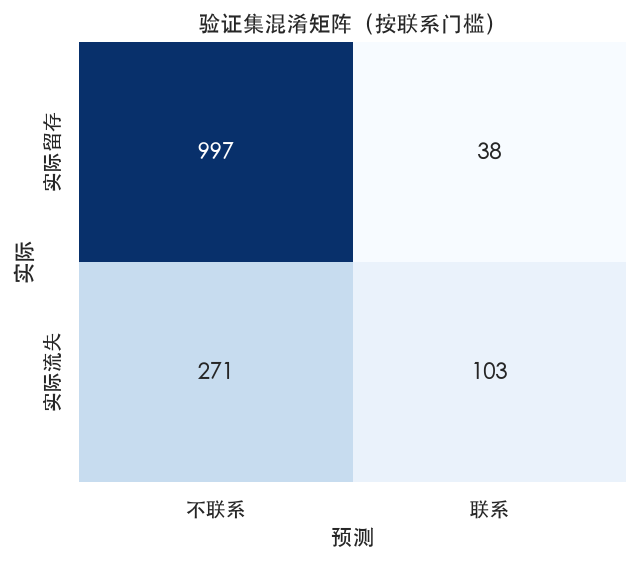

验证集按预测分从高到低的十等分（D1 最高）：
decile   n  actual_churn  mean_score
    D1 141      0.730496    0.922807
    D2 141      0.531915    0.784619
    D3 141      0.425532    0.647376
    D4 141      0.340426    0.496403
    D5 141      0.255319    0.338691
    D6 140      0.135714    0.195918
    D7 141      0.148936    0.093945
    D8 141      0.042553    0.036222
    D9 141      0.021277    0.011027
   D10 141      0.021277    0.003383


In [10]:
section("10. 验证集")
p_valid_lr = lr_model.predict_proba(lr_valid)[:, 1]
p_valid_lgb = lgb_model.predict_proba(X_valid)[:, 1]
majority_accuracy = float((y_valid == 0).mean())
print(f"验证集全部猜成不流失的准确率：{majority_accuracy:.2%}")

metrics = {
    "majority_accuracy": majority_accuracy,
    "logistic_regression_at_0.5": classification_report(y_valid, p_valid_lr, 0.5),
    "lightgbm_at_0.5": classification_report(y_valid, p_valid_lgb, 0.5),
}
print("逻辑回归 @0.5", json.dumps(metrics["logistic_regression_at_0.5"], ensure_ascii=False))
print("LightGBM @0.5", json.dumps(metrics["lightgbm_at_0.5"], ensure_ascii=False))

k_valid = max(1, int(round(len(y_valid) * 0.10)))
order_valid = np.argsort(-p_valid_lgb, kind="mergesort")
threshold = float(p_valid_lgb[order_valid[k_valid - 1]])
top_precision = float(y_valid[order_valid[:k_valid]].mean())
base_rate = float(y_valid.mean())
lift = top_precision / base_rate
metrics["contact_rule"] = {
    "k_valid": k_valid,
    "threshold": threshold,
    "top10_precision": top_precision,
    "validation_base_rate": base_rate,
    "lift_vs_random": lift,
}
print(
    f"验证集按概率从高到低取前 {k_valid} 人（{k_valid / len(y_valid):.1%}）。"
    f"其中真正流失 {top_precision:.1%}，验证集基线 {base_rate:.1%}，"
    f"是随机抽同样人数的 {lift:.2f} 倍（高出 {lift - 1:.2f} 倍）。"
)
print(f"锁定的概率门槛 = {threshold:.6f}。留出集只使用这个数。")
metrics["lightgbm_at_contact_threshold"] = classification_report(y_valid, p_valid_lgb, threshold)
print("LightGBM @门槛", json.dumps(metrics["lightgbm_at_contact_threshold"], ensure_ascii=False))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)
for ax, proba, title in (
    (axes[0], p_valid_lgb, "LightGBM 验证集 ROC"),
    (axes[1], p_valid_lr, "逻辑回归 验证集 ROC"),
):
    fpr, tpr, _ = roc_curve(y_valid, proba)
    auc = roc_auc_score(y_valid, proba)
    ax.plot(fpr, tpr, color="#E45756", label=f"AUC {auc:.3f}")
    ax.plot([0, 1], [0, 1], ls="--", color="#888888")
    ax.set_xlabel("假阳性率")
    ax.set_ylabel("真正率")
    ax.set_title(title)
    ax.legend(loc="lower right")
save_fig(fig, "11_roc_validation.png")

cm = confusion_matrix(y_valid, (p_valid_lgb >= threshold).astype(int))
fig, ax = plt.subplots(figsize=(4.8, 4.2), constrained_layout=True)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["不联系", "联系"],
    yticklabels=["实际留存", "实际流失"],
    ax=ax,
)
ax.set_title("验证集混淆矩阵（按联系门槛）")
ax.set_xlabel("预测")
ax.set_ylabel("实际")
save_fig(fig, "12_confusion_matrix.png")

rank = pd.Series(p_valid_lgb).rank(ascending=False, method="first")
decile = pd.qcut(rank, 10, labels=[f"D{i}" for i in range(1, 11)])
decile_table = (
    pd.DataFrame({"decile": decile, "y": y_valid, "p": p_valid_lgb})
    .groupby("decile", observed=True)
    .agg(n=("y", "size"), actual_churn=("y", "mean"), mean_score=("p", "mean"))
    .reset_index()
)
print("验证集按预测分从高到低的十等分（D1 最高）：")
print(decile_table.to_string(index=False))
decile_table.to_csv(OUT / "validation_deciles.csv", index=False)


## 11. 特征重要性是否和画像一致

主模型用 LightGBM 的 gain。浅树只解释规则。这里不用 SHAP。



11. 特征重要性
         feature         gain  split  gain_share
        Contract 10775.585868    235    0.200250
    TotalCharges  9713.441196   2385    0.180511
  MonthlyCharges  9153.841817   2301    0.170112
          tenure  8330.971709   1565    0.154820
  OnlineSecurity  4049.665130    186    0.075258
 InternetService  2080.509782    124    0.038663
     TechSupport  1241.340773    192    0.023069
   MultipleLines  1034.662192    227    0.019228
    OnlineBackup   998.832453    240    0.018562
 StreamingMovies   898.491720    168    0.016697
PaperlessBilling   823.297481    201    0.015300
   PaymentMethod   820.691802    169    0.015251
          gender   807.461267    216    0.015006
DeviceProtection   760.047897    193    0.014124
         Partner   621.715963    173    0.011554
     StreamingTV   586.291829    144    0.010895
   SeniorCitizen   485.429519    120    0.009021
      Dependents   432.743372    120    0.008042
    PhoneService   195.758844     41    0.003638
[图] outpu

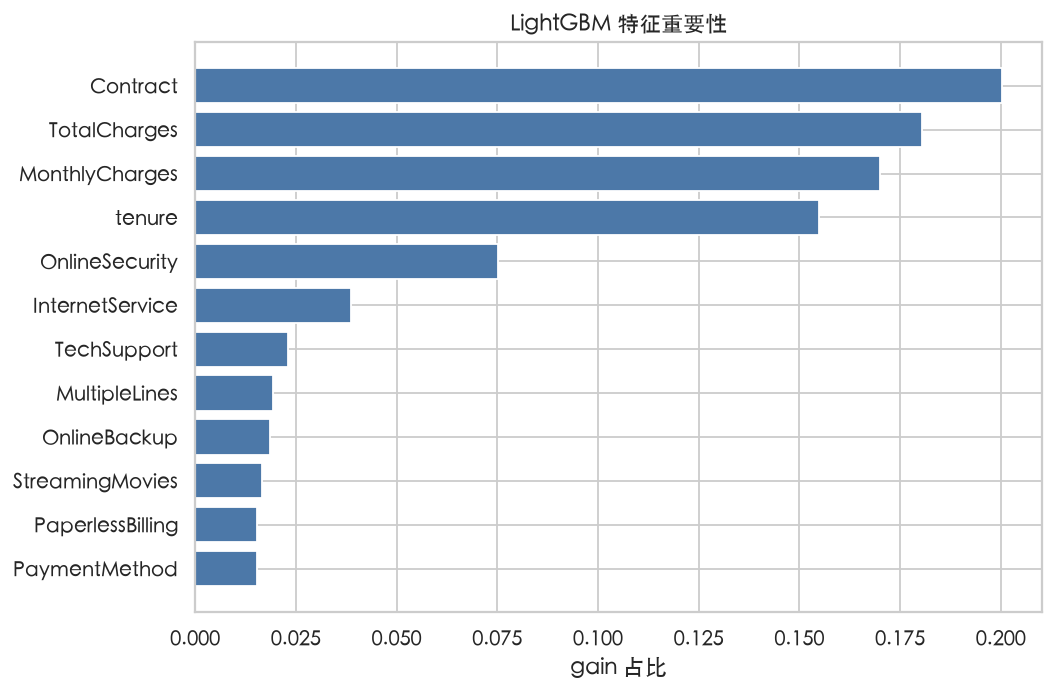

重要性前 8： ['Contract', 'TotalCharges', 'MonthlyCharges', 'tenure', 'OnlineSecurity', 'InternetService', 'TechSupport', 'MultipleLines']
  Contract 是否在前 8：是，排名 1
  tenure 是否在前 8：是，排名 4
  MonthlyCharges 是否在前 8：是，排名 3
  InternetService 是否在前 8：是，排名 6
  TechSupport 是否在前 8：是，排名 7
  OnlineSecurity 是否在前 8：是，排名 5
合同、在网月数、月费、网络类型、技术支持、在线安全都出现在重要性前 8，和画像一致。


In [11]:
section("11. 特征重要性")
gain = pd.DataFrame(
    {
        "feature": lgb_model.feature_name_,
        "gain": lgb_model.booster_.feature_importance(importance_type="gain"),
        "split": lgb_model.booster_.feature_importance(importance_type="split"),
    }
).sort_values("gain", ascending=False)
gain["gain_share"] = gain["gain"] / gain["gain"].sum()
print(gain.to_string(index=False))
gain.to_csv(OUT / "feature_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5.2), constrained_layout=True)
top_imp = gain.head(12).iloc[::-1]
ax.barh(top_imp["feature"], top_imp["gain_share"], color="#4C78A8")
ax.set_xlabel("gain 占比")
ax.set_title("LightGBM 特征重要性")
save_fig(fig, "13_feature_importance.png")

expected = ["Contract", "tenure", "MonthlyCharges", "InternetService", "TechSupport", "OnlineSecurity"]
ranked = gain.reset_index(drop=True)
top_names = set(ranked.head(8)["feature"])
print("重要性前 8：", list(ranked.head(8)["feature"]))
for name in expected:
    rank = int(ranked.index[ranked["feature"] == name][0]) + 1
    print(f"  {name} 是否在前 8：{'是' if name in top_names else '否'}，排名 {rank}")
missing = [name for name in expected if name not in top_names]
if missing:
    print("这些画像里的字段没有进前 8，下面看它们的实际名次，不改写成已经进前 8：", missing)
else:
    print("合同、在网月数、月费、网络类型、技术支持、在线安全都出现在重要性前 8，和画像一致。")


## 12–13. 给留出集打分

输入不含 `Churn`。联系标记使用验证集锁定的概率门槛。名单排好之后，才把真实流失拼回来做验收。前 20 人的原因只用原始字段里核对得上的高风险取值。


In [12]:
section("12–13. 留出集打分")
assert "Churn" not in X_holdout.columns
p_holdout = lgb_model.predict_proba(X_holdout)[:, 1]

scored = pd.DataFrame(
    {
        "customerID": holdout["customerID"],
        "churn_probability": p_holdout,
        "Contract": holdout["Contract"],
        "tenure": holdout["tenure"],
        "MonthlyCharges": holdout["MonthlyCharges"],
        "InternetService": holdout["InternetService"],
        "contact": np.where(p_holdout >= threshold, "Yes", "No"),
    }
)
scored = scored.sort_values(["churn_probability", "customerID"], ascending=[False, True]).reset_index(drop=True)
scored.to_csv(OUT / "contact_list.csv", index=False)
print(f"留出集 {len(scored)} 人，建议联系 {int((scored['contact'] == 'Yes').sum())} 人。")
print(scored.head(10).to_string(index=False))

train_charge_p75 = float(train["MonthlyCharges"].quantile(0.75))
important = set(gain.head(8)["feature"])


def reason_for(row: pd.Series) -> str:
    parts: list[str] = []
    if "Contract" in important and row["Contract"] == "Month-to-month":
        parts.append("月付合同")
    if "tenure" in important:
        parts.append(f"在网 {int(row['tenure'])} 个月")
    if "InternetService" in important and row["InternetService"] == "Fiber optic":
        parts.append("光纤")
    if "MonthlyCharges" in important and row["MonthlyCharges"] >= train_charge_p75:
        parts.append(f"月费 {row['MonthlyCharges']:.2f} 元，不低于训练集 75 分位 {train_charge_p75:.2f}")
    elif "MonthlyCharges" in important:
        parts.append(f"月费 {row['MonthlyCharges']:.2f} 元")
    raw_row = holdout.loc[holdout["customerID"] == row["customerID"]].iloc[0]
    if "TechSupport" in important and raw_row["TechSupport"] == "No":
        parts.append("未开通技术支持")
    if "OnlineSecurity" in important and raw_row["OnlineSecurity"] == "No":
        parts.append("未开通在线安全")
    if "PaymentMethod" in important and raw_row["PaymentMethod"] == "Electronic check":
        parts.append("电子支票付款")
    if not parts:
        parts.append("单项字段都不突出，高分来自特征组合，需要对照原始字段")
    return "；".join(parts)


top20 = scored.head(20).copy()
top20["reason"] = top20.apply(reason_for, axis=1)
top20.to_csv(OUT / "top20_reasons.csv", index=False)
print("\n概率最高的 20 人：")
print(top20[["customerID", "churn_probability", "contact", "reason"]].to_string(index=False))

audit = scored.merge(
    holdout[["customerID", "Churn"]],
    on="customerID",
    how="left",
    validate="one_to_one",
)
contacted = audit[audit["contact"] == "Yes"]
hit = int((contacted["Churn"] == "Yes").sum())
holdout_base = float((audit["Churn"] == "Yes").mean())
contact_precision = hit / len(contacted)
contact_recall = hit / int((audit["Churn"] == "Yes").sum())
holdout_lift = contact_precision / holdout_base
print(
    f"验收：联系名单 {len(contacted)} 人，后来真的流失 {hit} 人，"
    f"命中率 {contact_precision:.1%}，召回 {contact_recall:.1%}。"
    f"留出集流失率 {holdout_base:.1%}，名单是随机联系的 {holdout_lift:.2f} 倍。"
)
audit.to_csv(OUT / "holdout_audit.csv", index=False)

p_holdout_check = lgb_model.predict_proba(X_holdout)[:, 1]
bundle = {
    "model_type": "lightgbm",
    "model": lgb_model,
    "feature_columns": list(X_train.columns),
    "categorical_columns": CAT_COLS,
    "categorical_levels": cat_levels,
    "contract_map": CONTRACT_MAP,
    "threshold": threshold,
    "threshold_rule": "验证集预测概率从高到低第 10% 那位客户的概率；分数大于等于该值则联系",
    "scale_pos_weight": scale_pos_weight,
    "random_state": RANDOM_STATE,
    "positive_class": "Churn=Yes",
    "train_monthly_charges_p75": train_charge_p75,
}
model_path = MODEL_DIR / "churn_lgbm.joblib"
joblib.dump(bundle, model_path)
lgb_model.booster_.save_model(str(MODEL_DIR / "churn_lgbm.txt"))

reloaded = joblib.load(model_path)
X_check, _ = build_lgb_frame(holdout, reloaded["categorical_levels"])
X_check = X_check[reloaded["feature_columns"]]
reloaded_proba = reloaded["model"].predict_proba(X_check)[:, 1]
if not np.allclose(reloaded_proba, p_holdout_check, rtol=1e-6, atol=1e-6):
    raise AssertionError("重新加载的模型打分和当前模型不一致")
print(f"模型已保存并完成回读校验：{model_path.relative_to(ROOT)}")

metrics["holdout"] = {
    "n": int(len(audit)),
    "contacted": int(len(contacted)),
    "hit": hit,
    "precision": contact_precision,
    "recall": contact_recall,
    "base_rate": holdout_base,
    "lift_vs_random": holdout_lift,
    "roc_auc": float(roc_auc_score(y_holdout, p_holdout)),
}
metrics["odds_ratio_month_to_month_vs_two_year"] = {
    "adjusted": or_month,
    "ci95": list(or_ci),
    "unadjusted": raw_or,
    "adjusted_one_year_vs_two_year": or_one,
}
metrics["versions"] = versions
(OUT / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")

model_card = f"""主模型：LightGBM
文件：outputs/models/churn_lgbm.joblib（打分用这个，里面有类别水平和联系门槛）
原生模型：outputs/models/churn_lgbm.txt
positive 类：Churn = Yes
random_state：{RANDOM_STATE}
scale_pos_weight：{scale_pos_weight:.4f}（训练集未流失 / 流失）
联系门槛：{threshold:.6f}（在验证集上按最高 10% 锁定，留出集没有改）
验证集前 10% 真实流失比例：{top_precision:.1%}，是随机的 {lift:.2f} 倍
留出集名单命中率：{contact_precision:.1%}，召回 {contact_recall:.1%}，是随机的 {holdout_lift:.2f} 倍
月付相对两年合同的调整后几率比：{or_month:.2f}（95% 区间 {or_ci[0]:.2f}–{or_ci[1]:.2f}）
验证集 AUC：逻辑回归 {metrics['logistic_regression_at_0.5']['roc_auc']:.3f}，LightGBM {metrics['lightgbm_at_0.5']['roc_auc']:.3f}。名单用 LightGBM。

画像和重要性：Contract、tenure、MonthlyCharges、InternetService、TechSupport、OnlineSecurity 都在 gain 前 8。
TotalCharges 的 gain 排第 {int(ranked.index[ranked['feature'] == 'TotalCharges'][0]) + 1}，它和 tenure×MonthlyCharges 的相关系数是 {charge_corr:.3f}，不是另一根可以单独操作的杠杆。
PaymentMethod 排第 {int(ranked.index[ranked['feature'] == 'PaymentMethod'][0]) + 1}。电子支票的单变量流失率很高，但大部分已经被月付合同解释掉了。
逻辑回归在控制合同、在网月数和月费之后，在线安全和技术支持的系数不再显著。单变量差距仍然大，是因为没开通的人集中在月付和光纤。运营按人群做动作，不把这个系数当成独立因果。

打分时不要传入 Churn。Contract 用 contract_map 编成 0/1/2，其余类别列套用 categorical_levels。
概率来自带类别权重的模型，适合排序和套用这个门槛，不宜直接当成未经校准的真实流失频率。
"""
(OUT / "model_card.txt").write_text(model_card, encoding="utf-8")
print(model_card)
print("完成。")



12–13. 留出集打分
留出集 1409 人，建议联系 141 人。
customerID  churn_probability       Contract  tenure  MonthlyCharges InternetService contact
1069-XAIEM           0.988306 Month-to-month       1           85.05     Fiber optic     Yes
9248-OJYKK           0.987587 Month-to-month       1           76.45     Fiber optic     Yes
6861-XWTWQ           0.985076 Month-to-month       7           99.25     Fiber optic     Yes
2254-DLXRI           0.983692 Month-to-month       1           79.15     Fiber optic     Yes
9507-EXLTT           0.982822 Month-to-month       1           79.35     Fiber optic     Yes
2514-GINMM           0.982615 Month-to-month       1           79.50     Fiber optic     Yes
2609-IAICY           0.982552 Month-to-month       1           77.15     Fiber optic     Yes
6230-BSUXY           0.981195 Month-to-month       1           85.00     Fiber optic     Yes
0655-RBDUG           0.980003 Month-to-month       7           98.05     Fiber optic     Yes
5178-LMXOP           0.978149 Mon

模型已保存并完成回读校验：outputs/models/churn_lgbm.joblib
主模型：LightGBM
文件：outputs/models/churn_lgbm.joblib（打分用这个，里面有类别水平和联系门槛）
原生模型：outputs/models/churn_lgbm.txt
positive 类：Churn = Yes
random_state：42
scale_pos_weight：2.7690（训练集未流失 / 流失）
联系门槛：0.863337（在验证集上按最高 10% 锁定，留出集没有改）
验证集前 10% 真实流失比例：73.0%，是随机的 2.75 倍
留出集名单命中率：74.5%，召回 28.1%，是随机的 2.81 倍
月付相对两年合同的调整后几率比：4.66（95% 区间 2.95–7.36）
验证集 AUC：逻辑回归 0.836，LightGBM 0.824。名单用 LightGBM。

画像和重要性：Contract、tenure、MonthlyCharges、InternetService、TechSupport、OnlineSecurity 都在 gain 前 8。
TotalCharges 的 gain 排第 2，它和 tenure×MonthlyCharges 的相关系数是 1.000，不是另一根可以单独操作的杠杆。
PaymentMethod 排第 12。电子支票的单变量流失率很高，但大部分已经被月付合同解释掉了。
逻辑回归在控制合同、在网月数和月费之后，在线安全和技术支持的系数不再显著。单变量差距仍然大，是因为没开通的人集中在月付和光纤。运营按人群做动作，不把这个系数当成独立因果。

打分时不要传入 Churn。Contract 用 contract_map 编成 0/1/2，其余类别列套用 categorical_levels。
概率来自带类别权重的模型，适合排序和套用这个门槛，不宜直接当成未经校准的真实流失频率。

完成。
